# Homework 4 - Time Series Classification

**Name:** Nakul Kumbria

**GitHub Username:** nakicool007

**USC ID:** 6748597520

## Setup

In [11]:
from pathlib import Path
import shutil

# Support Jupyter launched from the repository root or notebook directory.
cwd = Path.cwd().resolve()
root = next((candidate for candidate in (cwd, *cwd.parents)
             if (candidate / "data" / "AReM" / "bending1").is_dir()), None)
if root is None:
    raise FileNotFoundError("Open this notebook inside the HW4 repository, with data/AReM present.")
data_root = root / "data" / "AReM"
processed_root = root / "data" / "processed"
processed_root.mkdir(parents=True, exist_ok=True)
activities = ("bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking")


## (a) AReM Dataset

I used the [AReM dataset from UCI](https://archive.ics.uci.edu/dataset/366/activity+recognition+system+based+on+multisensor+data+fusion). The files are in `data/AReM/`. There are 88 instances in seven folders: 7 in bending1, 6 in bending2, and 15 each in cycling, lying, sitting, standing, and walking.

Each file has a time column and six sensor columns: `avg_rss12`, `var_rss12`, `avg_rss13`, `var_rss13`, `avg_rss23`, and `var_rss23`.

The assignment says each instance has 480 observations. I checked the files and found that `sitting/dataset8.csv` has 479, while the other 87 files have 480. I kept the 479 values for that file instead of adding a made-up value.

Dataset citation: Palumbo, F., Gallicchio, C., Pucci, R., & Micheli, A. (2016). *Activity Recognition system based on Multisensor data fusion (AReM)*. UCI Machine Learning Repository. https://doi.org/10.24432/C5SS33. License: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).


In [12]:
import csv
import math
from statistics import mean, median, stdev, quantiles
from IPython.display import HTML, display

series_names = [
    "avg_rss12", "var_rss12", "avg_rss13",
    "var_rss13", "avg_rss23", "var_rss23",
]

def read_time_series(path):
    rows = []
    for line in path.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        # Remove trailing commas and allow either commas or spaces.
        values = line.rstrip(",").split(",") if "," in line else line.split()
        if len(values) != 7:
            raise ValueError(f"Unexpected number of columns in {path}")
        rows.append([float(value) for value in values])

    if len(rows) != 480 and not (path.parent.name == "sitting" and path.name == "dataset8.csv" and len(rows) == 479):
        raise ValueError(f"Unexpected number of observations in {path}: {len(rows)}")
    if not all(math.isfinite(value) for row in rows for value in row):
        raise ValueError(f"Missing or non-finite values in {path}")
    # The first column is time, so only keep the six sensor columns.
    return list(zip(*(row[1:] for row in rows)))

In [13]:
source_files = [path for activity in activities
                for path in (data_root / activity).glob("dataset*.csv")]
assert len(source_files) == 88
row_counts = {}
for source in source_files:
    series = read_time_series(source)
    assert len(series) == 6
    row_counts[source.relative_to(data_root).as_posix()] = len(series[0])
assert sum(count == 480 for count in row_counts.values()) == 87
assert row_counts["sitting/dataset8.csv"] == 479
print("Validated 88 instances in seven activity folders, each with six sensor series.")
print("87 instances have 480 observations; sitting/dataset8.csv has 479 original observations.")


Validated 88 instances in seven activity folders, each with six sensor series.
87 instances have 480 observations; sitting/dataset8.csv has 479 original observations.


## (b) Training and Test Split

I used datasets 1 and 2 from bending1 and bending2 as test data. For the other five activities, I used datasets 1, 2, and 3 as test data. The remaining files are training data, as specified in the question.


In [14]:
train_files, test_files = [], []

for activity in activities:
    files = sorted(
        (data_root / activity).glob("dataset*.csv"),
        key=lambda path: int(path.stem.removeprefix("dataset")),
    )
    expected_count = 7 if activity == "bending1" else 6 if activity == "bending2" else 15
    actual_ids = {int(path.stem.removeprefix("dataset")) for path in files}
    assert actual_ids == set(range(1, expected_count + 1)), f"Unexpected files in {activity}"

    test_ids = {1, 2} if activity in {"bending1", "bending2"} else {1, 2, 3}
    for source in files:
        instance_id = int(source.stem.removeprefix("dataset"))
        if instance_id in test_ids:
            test_files.append(source)
        else:
            train_files.append(source)

assert len(train_files) == 69
assert len(test_files) == 19
assert set(train_files).isdisjoint(test_files)

### Saving the Split

I copied the files into `data/train/` and `data/test/`, keeping a folder for each activity. There are 69 training instances and 19 test instances. The code also checks that the copied files match the originals.


In [15]:
for split, files in (("train", train_files), ("test", test_files)):
    expected = {Path(source.parent.name) / source.name for source in files}
    split_root = root / "data" / split
    existing = {path.relative_to(split_root) for path in split_root.rglob("*.csv")}
    if existing - expected:
        raise ValueError(f"Unexpected files in {split_root}: {existing - expected}")
    for source in files:
        destination = split_root / source.parent.name / source.name
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(source, destination)
        assert destination.read_bytes() == source.read_bytes()
    actual = {path.relative_to(split_root) for path in split_root.rglob("*.csv")}
    assert actual == expected, f"Incorrect membership in {split}"

print(f"Training instances: {len(train_files)}")
print(f"Test instances: {len(test_files)}")


Training instances: 69
Test instances: 19


## (c) Feature Extraction

### (i) Common Time-Domain Features

Time-domain features summarize a time series so we do not have to use every observation as a separate input. Some common features are:

- Minimum and maximum: the smallest and largest values.
- Mean and median: the average and middle value.
- Standard deviation and variance: how much the values vary.
- First and third quartiles: the 25th and 75th percentiles.
- Range and interquartile range: the differences between the extremes and between the quartiles.
- RMS and energy: measures of the size of the readings, using squared values.
- Mean absolute change: the average size of the change between consecutive readings.
- Autocorrelation and trend: how readings relate at different time lags and whether they increase or decrease over time.
- Peak and crossing counts: the number of local peaks or crossings of a reference value.
- Skewness and kurtosis: the asymmetry and tail heaviness of the distribution.

For this question, I used minimum, maximum, mean, median, standard deviation, and the first and third quartiles. Seven features for each of the six series gives 42 features per instance.


### (ii) Extracting the Features

I calculated the seven features for each sensor series without normalizing the values. I used sample standard deviation, which divides by n - 1, and linearly interpolated quartiles.

The numbers 1 through 6 in the column names follow the sensor order listed in part (a). For example, `min_1` is the minimum of `avg_rss12`, and `q1_6` is the first quartile of `var_rss23`.

The reader defined earlier handles files with spaces instead of commas and extra commas at the ends of rows. For `sitting/dataset8.csv`, I used all 479 available observations.


In [16]:
feature_rows = []
instance_info = []

for activity in activities:
    files = sorted(
        (data_root / activity).glob("dataset*.csv"),
        key=lambda path: int(path.stem.removeprefix("dataset")),
    )
    for source in files:
        instance = len(feature_rows) + 1
        features = {"Instance": instance}
        for number, values in enumerate(read_time_series(source), start=1):
            q1, _, q3 = quantiles(values, n=4, method="inclusive")
            statistics = {
                "min": min(values),
                "max": max(values),
                "mean": mean(values),
                "median": median(values),
                "std": stdev(values),
                "q1": q1,
                "q3": q3,
            }
            for statistic, value in statistics.items():
                features[f"{statistic}_{number}"] = value
        feature_rows.append(features)
        instance_info.append({
            "Instance": instance,
            "activity": activity,
            "file": source.name,
            "split": "test" if source in test_files else "train",
        })

feature_columns = list(feature_rows[0])[1:]
X_train = [[row[column] for column in feature_columns]
           for row, info in zip(feature_rows, instance_info) if info["split"] == "train"]
X_test = [[row[column] for column in feature_columns]
          for row, info in zip(feature_rows, instance_info) if info["split"] == "test"]
y_train = [info["activity"] for info in instance_info if info["split"] == "train"]
y_test = [info["activity"] for info in instance_info if info["split"] == "test"]

assert len(feature_rows) == 88 and len(feature_columns) == 42
assert len(X_train) == 69 and len(X_test) == 19
assert all(math.isfinite(row[column]) for row in feature_rows for column in feature_columns)
print(f"Feature dataset: {len(feature_rows)} instances, {len(feature_columns)} features")
print(f"Training set: {len(X_train)} instances; test set: {len(X_test)} instances")

Feature dataset: 88 instances, 42 features
Training set: 69 instances; test set: 19 instances


In [17]:
with (processed_root / "features.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=["Instance"] + feature_columns)
    writer.writeheader()
    writer.writerows(feature_rows)

# Keep labels and split information separate from the 42 numeric features.
with (processed_root / "instance_metadata.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(instance_info[0]))
    writer.writeheader()
    writer.writerows(instance_info)

# Preview the first five instances. The full table is saved in features.csv.
preview_columns = ["Instance"] + feature_columns[:7] + ["..."] + feature_columns[-2:]
header = "".join(f"<th>{column}</th>" for column in preview_columns)
body = ""
for row in feature_rows[:5]:
    cells = []
    for column in preview_columns:
        value = "..." if column == "..." else str(row[column]) if column == "Instance" else f"{row[column]:.4f}"
        cells.append(f"<td>{value}</td>")
    body += "<tr>" + "".join(cells) + "</tr>"
display(HTML('<div style="overflow-x:auto"><table><thead><tr>' + header + '</tr></thead><tbody>' + body + '</tbody></table></div>'))

Instance,min_1,max_1,mean_1,median_1,std_1,q1_1,q3_1,...,q1_6,q3_6
1,37.2500,45.0000,40.6248,40.5000,1.4770,39.2500,42.0000,...,0.0000,1.3000
2,38.0000,45.6700,42.8128,42.5000,1.4355,42.0000,43.6700,...,0.0000,1.3000
3,35.0000,47.4000,43.9545,44.3300,1.5588,43.0000,45.0000,...,0.0000,0.9400
4,33.0000,47.7500,42.1798,43.5000,3.6707,39.1500,45.0000,...,0.0000,1.0000
5,33.0000,45.7500,41.6781,41.7500,2.2435,41.3300,42.7500,...,0.0000,0.5000


The result has 88 rows and 42 feature columns, plus the instance number. I saved it in `data/processed/features.csv`. The activity labels, filenames, and train/test assignments are in `data/processed/instance_metadata.csv`.

The preview shows the first five instances and rounds the values to four decimal places. The CSV keeps the full precision.


### (iii) Standard Deviations and Bootstrap Confidence Intervals

I calculated the sample standard deviation of each feature across the 88 instances. For example, the standard deviation of `min_1` measures how much the minimum of the first sensor series changes between instances. This is different from the standard deviation within a single sensor series in part (ii).

For the 90% confidence intervals, I sampled 88 instances with replacement and recalculated the standard deviations. I repeated this 10,000 times and used the 5th and 95th percentiles as the interval limits. I used seed 42 so the results stay the same when I rerun the notebook. Each repetition uses the same sampled instance indices for all 42 features.


In [18]:
import random

n_bootstrap = 10_000
rng = random.Random(42)
n_instances = len(feature_rows)

feature_values = {
    column: [row[column] for row in feature_rows]
    for column in feature_columns
}
feature_std = {column: stdev(values) for column, values in feature_values.items()}
bootstrap_std = {column: [] for column in feature_columns}

# Centering preserves standard deviations and improves numerical stability.
centered_values = {
    column: [value - mean(values) for value in values]
    for column, values in feature_values.items()
}

for _ in range(n_bootstrap):
    sampled_indices = rng.choices(range(n_instances), k=n_instances)
    for column in feature_columns:
        sample = [centered_values[column][index] for index in sampled_indices]
        sample_sum = math.fsum(sample)
        sum_squares = math.fsum(value * value for value in sample)
        variance = (sum_squares - sample_sum ** 2 / n_instances) / (n_instances - 1)
        bootstrap_std[column].append(math.sqrt(max(variance, 0.0)))

print(f"Completed {n_bootstrap:,} bootstrap samples for {len(feature_columns)} features.")

Completed 10,000 bootstrap samples for 42 features.


In [19]:
def percentile(values, probability):
    ordered = sorted(values)
    position = (len(ordered) - 1) * probability
    lower = math.floor(position)
    upper = math.ceil(position)
    return ordered[lower] + (position - lower) * (ordered[upper] - ordered[lower])

std_ci_rows = []
for column in feature_columns:
    std_ci_rows.append({
        "feature": column,
        "std": feature_std[column],
        "ci_90_lower": percentile(bootstrap_std[column], 0.05),
        "ci_90_upper": percentile(bootstrap_std[column], 0.95),
    })

assert len(std_ci_rows) == 42
assert all(0 <= row["ci_90_lower"] <= row["ci_90_upper"] for row in std_ci_rows)
assert all(math.isfinite(value) for row in std_ci_rows for key, value in row.items() if key != "feature")

with (processed_root / "feature_std_ci.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(std_ci_rows[0]))
    writer.writeheader()
    writer.writerows(std_ci_rows)

header = "<tr><th>Feature</th><th>Standard deviation</th><th>90% CI lower</th><th>90% CI upper</th></tr>"
body = ""
for row in std_ci_rows:
    body += (
        f"<tr><td>{row['feature']}</td>"
        f"<td>{row['std']:.4f}</td>"
        f"<td>{row['ci_90_lower']:.4f}</td>"
        f"<td>{row['ci_90_upper']:.4f}</td></tr>"
    )
display(HTML("<table><thead>" + header + "</thead><tbody>" + body + "</tbody></table>"))

Feature,Standard deviation,90% CI lower,90% CI upper
min_1,9.5700,8.2646,10.7871
max_1,4.3944,3.3279,5.2927
mean_1,5.3357,4.7293,5.8694
median_1,5.4401,4.8076,5.9938
std_1,1.7722,1.5701,1.9484
q1_1,6.1536,5.5834,6.6379
q3_1,5.1389,4.3478,5.8331
min_2,0.0000,0.0000,0.0000
max_2,5.0627,4.6168,5.3996
mean_2,1.5742,1.3929,1.7045


The table gives the standard deviation and 90% bootstrap interval for each feature. Wider intervals mean more uncertainty in the estimate. I used all 88 instances for this part, including the training and test instances. The bootstrap assumes the instances are independent.

I saved these results in `data/processed/feature_std_ci.csv`.


### (iv) Selecting Three Important Features

I would choose mean, standard deviation, and maximum.

- Mean gives the average sensor reading and could help separate activities with different overall readings.
- Standard deviation shows how much the readings change. I would expect this to help distinguish movement, such as walking, from sitting or lying down.
- Maximum captures a high reading that might be missed by looking only at the average.

These features cover the average level, variation, and highest reading. Using them for all six series would give 18 features per instance. This is my initial choice; I would need to compare their performance on the training data to know whether they work best.


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### (i) Scatter Plots of the Selected Features

I used the three features I chose in 1(c)(iv): **mean, standard deviation, and maximum**. I took these features from time series **1, 2, and 6**, so each instance has nine features. I only used the training set, which has 69 instances. I grouped `bending1` and `bending2` together as bending, giving 9 bending instances and 60 instances from the other activities.

I plotted each feature against the others in the scatterplot matrix below. Each point is one training instance. The orange triangles represent bending, and the blue circles represent the other activities. The plots on the diagonal are histograms of each feature. The number in each feature name refers to the time series, so `mean_1` is the mean of series 1 and `std_6` is the standard deviation of series 6.


Training instances: 69 (9 bending, 60 other activities); selected features: 9.


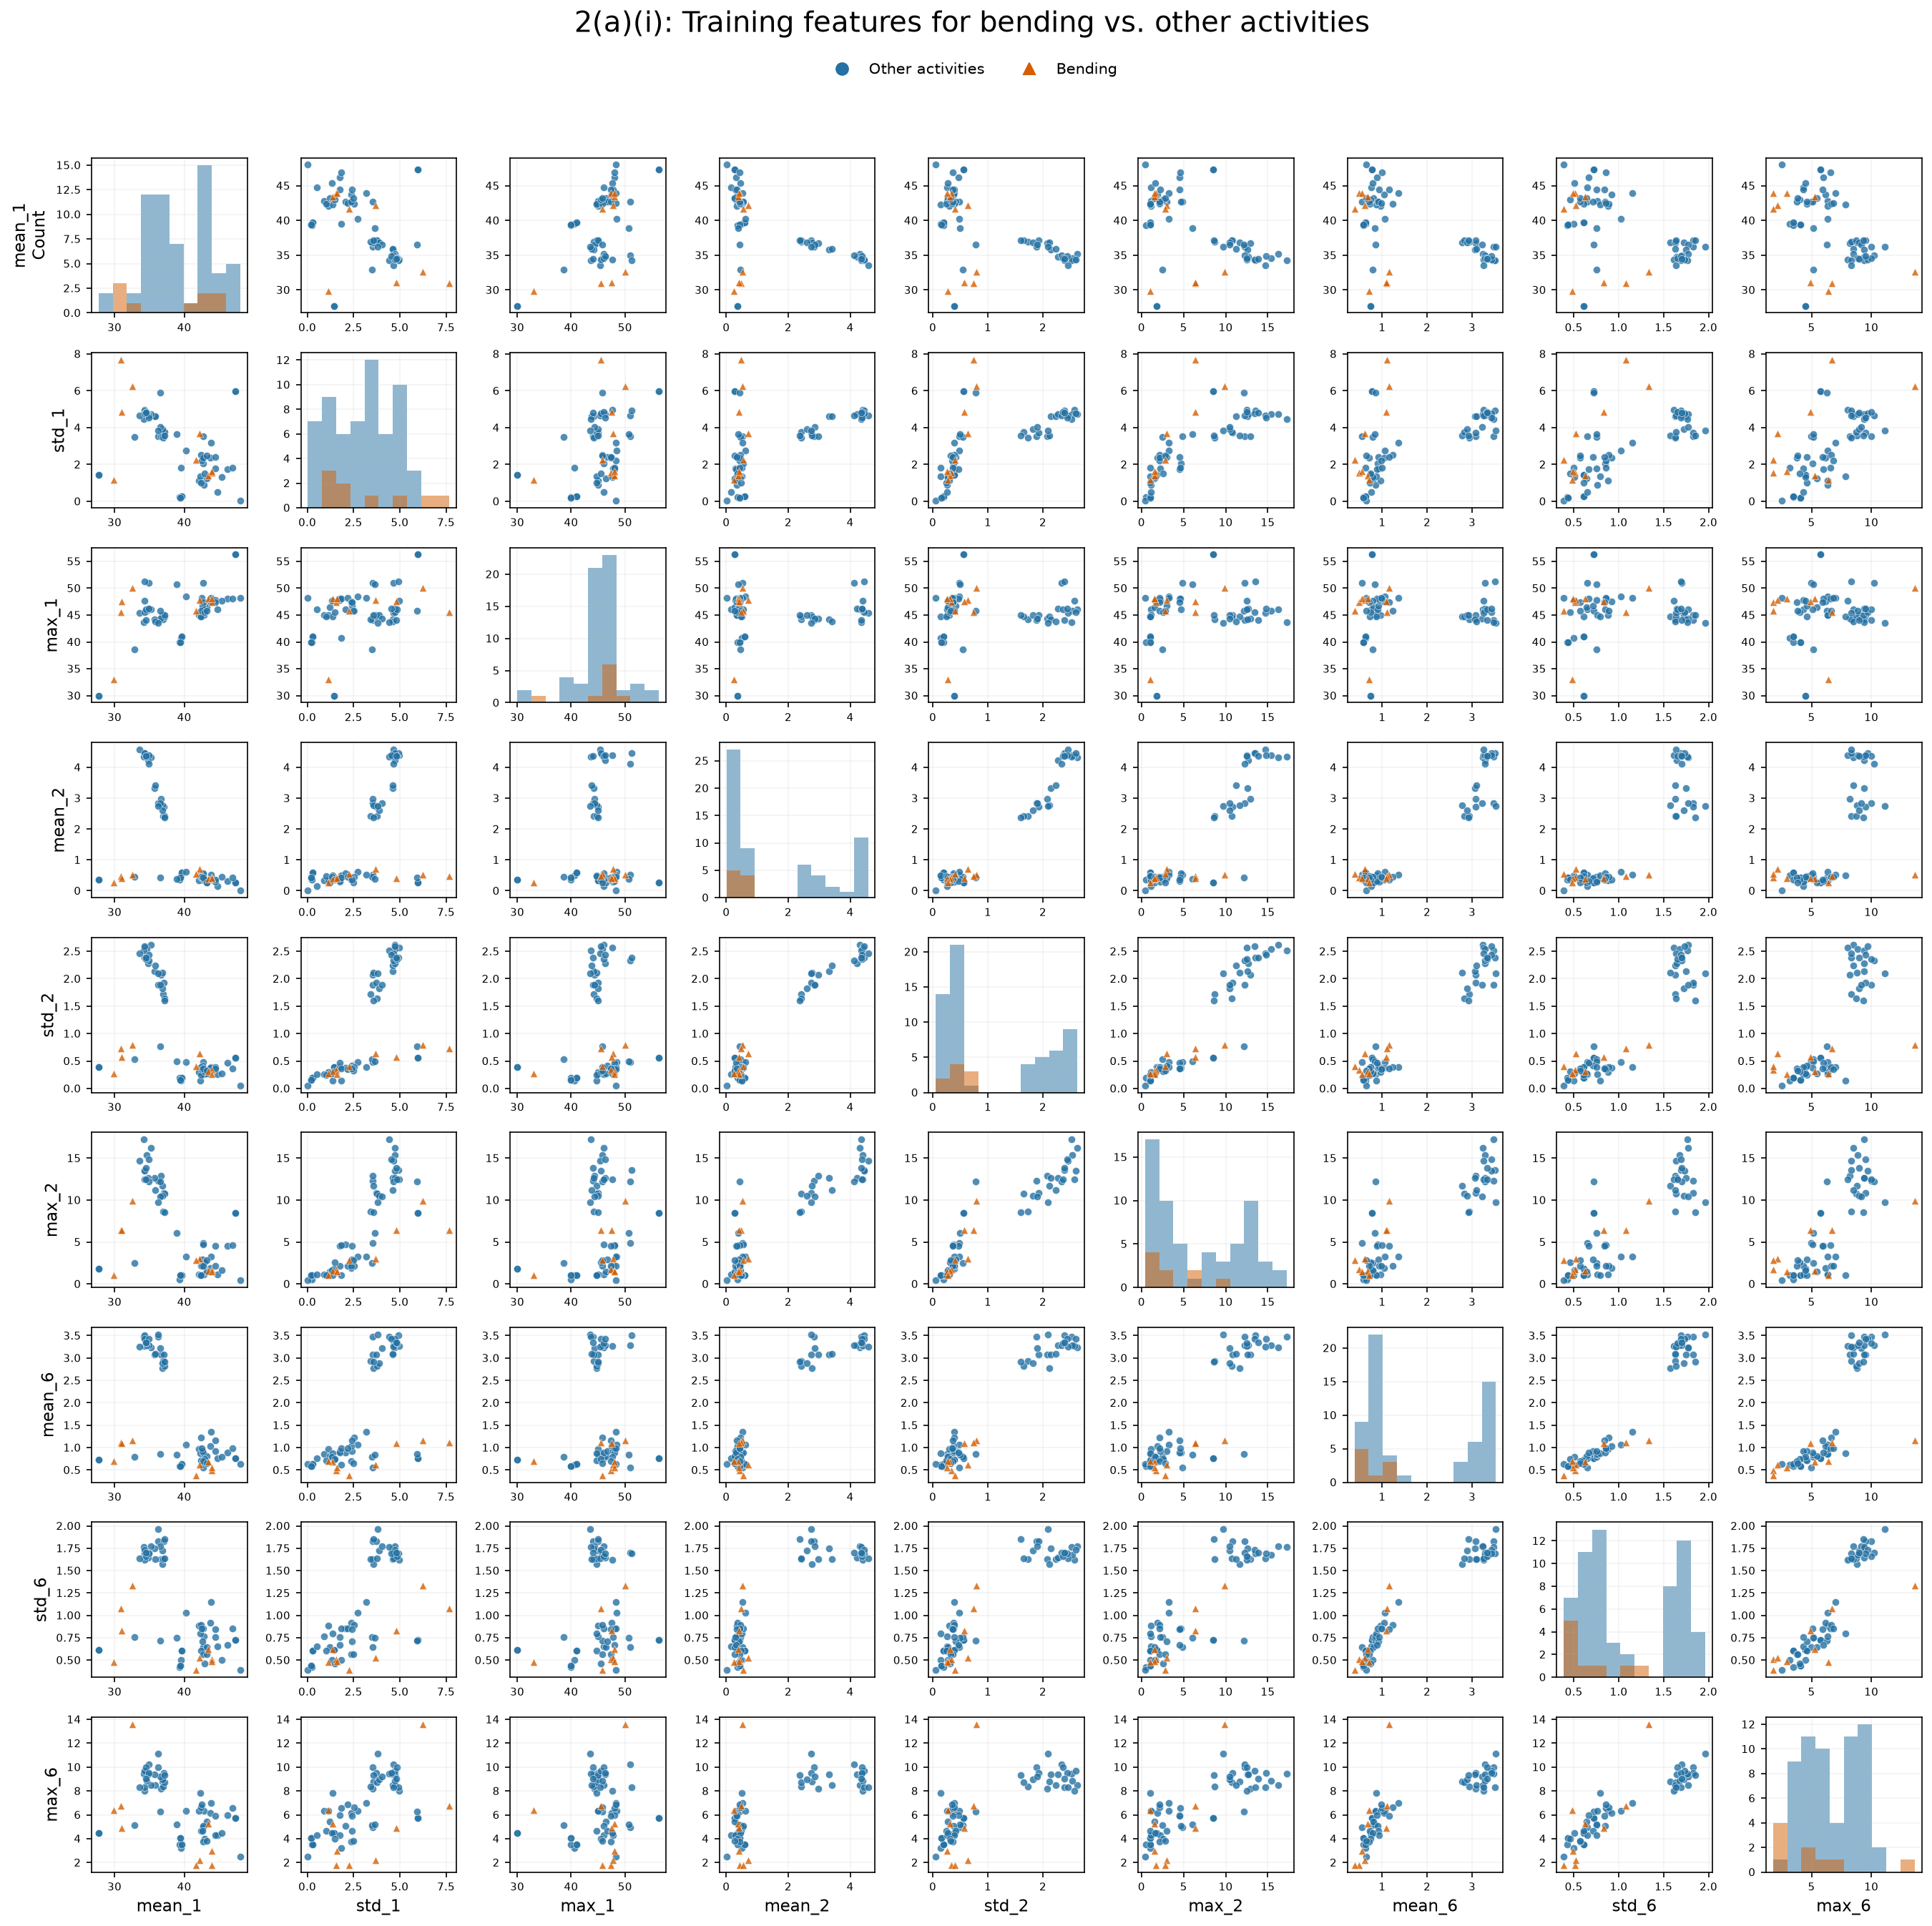

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Reuse the features and split from Question 1; exclude all test instances.
selected_features = [f"{statistic}_{series}"
                     for series in (1, 2, 6)
                     for statistic in ("mean", "std", "max")]
metadata_by_id = {info["Instance"]: info for info in instance_info}
plot_rows = []
for row in feature_rows:
    info = metadata_by_id[row["Instance"]]
    if info["split"] == "train":
        label = "Bending" if info["activity"] in {"bending1", "bending2"} else "Other activities"
        plot_rows.append((row, label))

assert len(plot_rows) == 69
assert sum(label == "Bending" for _, label in plot_rows) == 9
assert len(selected_features) == 9

styles = {
    "Other activities": {"color": "#2471A3", "marker": "o"},
    "Bending": {"color": "#D55E00", "marker": "^"},
}
fig, axes = plt.subplots(9, 9, figsize=(18, 18))
for i, y_feature in enumerate(selected_features):
    for j, x_feature in enumerate(selected_features):
        ax = axes[i, j]
        for label, style in styles.items():
            rows = [row for row, group in plot_rows if group == label]
            x = [row[x_feature] for row in rows]
            if i == j:
                # Use common bin edges for the two classes.
                all_x = [row[x_feature] for row, _ in plot_rows]
                lo, hi = min(all_x), max(all_x)
                bins = [lo + (hi - lo) * k / 10 for k in range(11)]
                ax.hist(x, bins=bins, color=style["color"], alpha=0.5)
            else:
                ax.scatter(x, [row[y_feature] for row in rows],
                           s=24, alpha=0.8, edgecolors="white", linewidths=0.3,
                           **style)
        if i == 8:
            ax.set_xlabel(x_feature, fontsize=11)
        if j == 0:
            ax.set_ylabel(y_feature if i != j else f"{y_feature}\nCount", fontsize=11)
        ax.tick_params(labelsize=7)
        ax.grid(alpha=0.15)

handles = [Line2D([], [], linestyle="", markersize=8, label=label,
                  color=style["color"], marker=style["marker"])
           for label, style in styles.items()]
fig.suptitle("2(a)(i): Training features for bending vs. other activities", fontsize=19, y=0.995)
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.975), ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
figure_root = root / "figures"
figure_root.mkdir(exist_ok=True)
fig.savefig(figure_root / "2a_i_scatter_matrix.png", dpi=150, bbox_inches="tight")
print("Training instances: 69 (9 bending, 60 other activities); selected features: 9.")
plt.show()


From the plots, I noticed that bending usually has low mean and standard deviation values in series 2 and 6. These features seem useful for separating bending from activities with higher values. However, some bending points overlap with the other activities, so there is no clear separation in every plot. I would need to fit and evaluate the classifier to see how well these features work together.


#### (ii) Splitting Each Time Series into Two Parts

I split each of the six time series into two halves. Each instance now has 12 shorter time series instead of 6. Most of the series have 480 observations, so I put 240 in each half. For `sitting/dataset8.csv`, I used 239 observations in the first half and 240 in the second half because it has 479 observations.

I used mean, standard deviation, and maximum again, taking these features from both halves of series 1, 2, and 6. This gives 18 features for each of the 69 training instances. I grouped the two bending activities together, just like in part (i). Orange triangles show bending, and blue circles show the other activities.

I made a scatterplot matrix for each half below. In the feature names, `h1` means the first half and `h2` means the second half. For example, `mean_1_h2` is the mean of the second half of series 1. I also saved a full matrix that compares all 18 features.


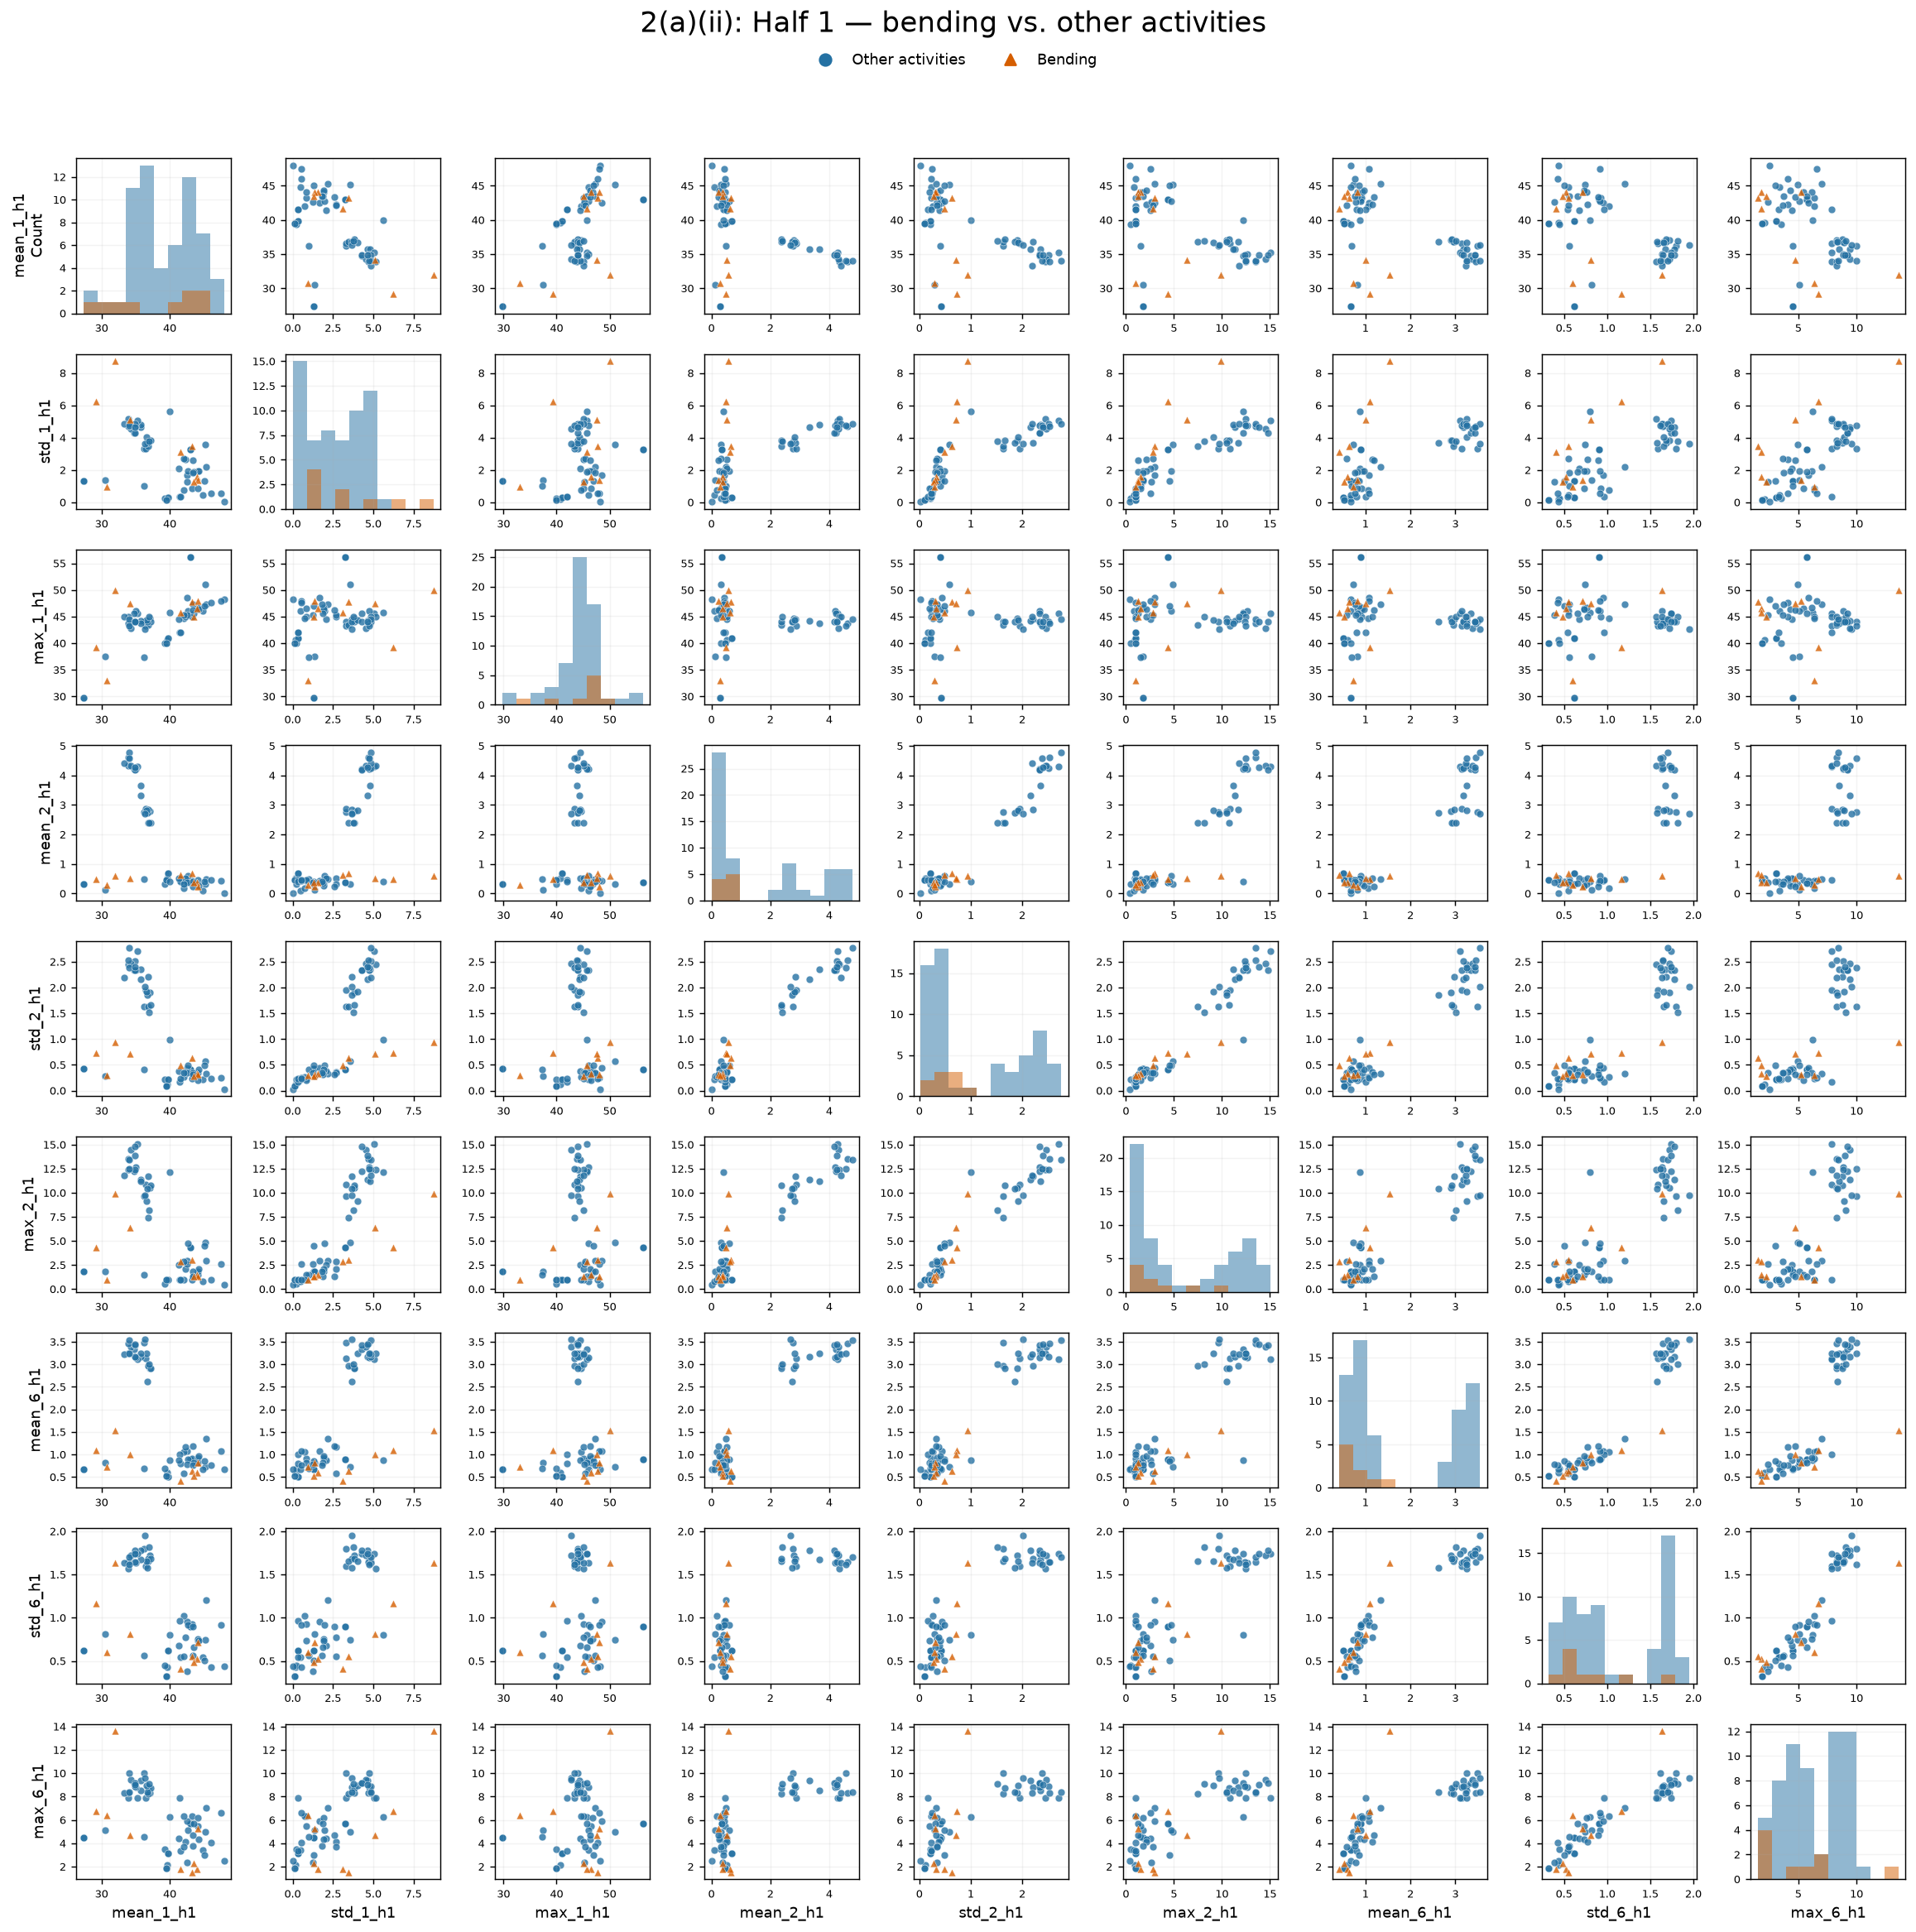

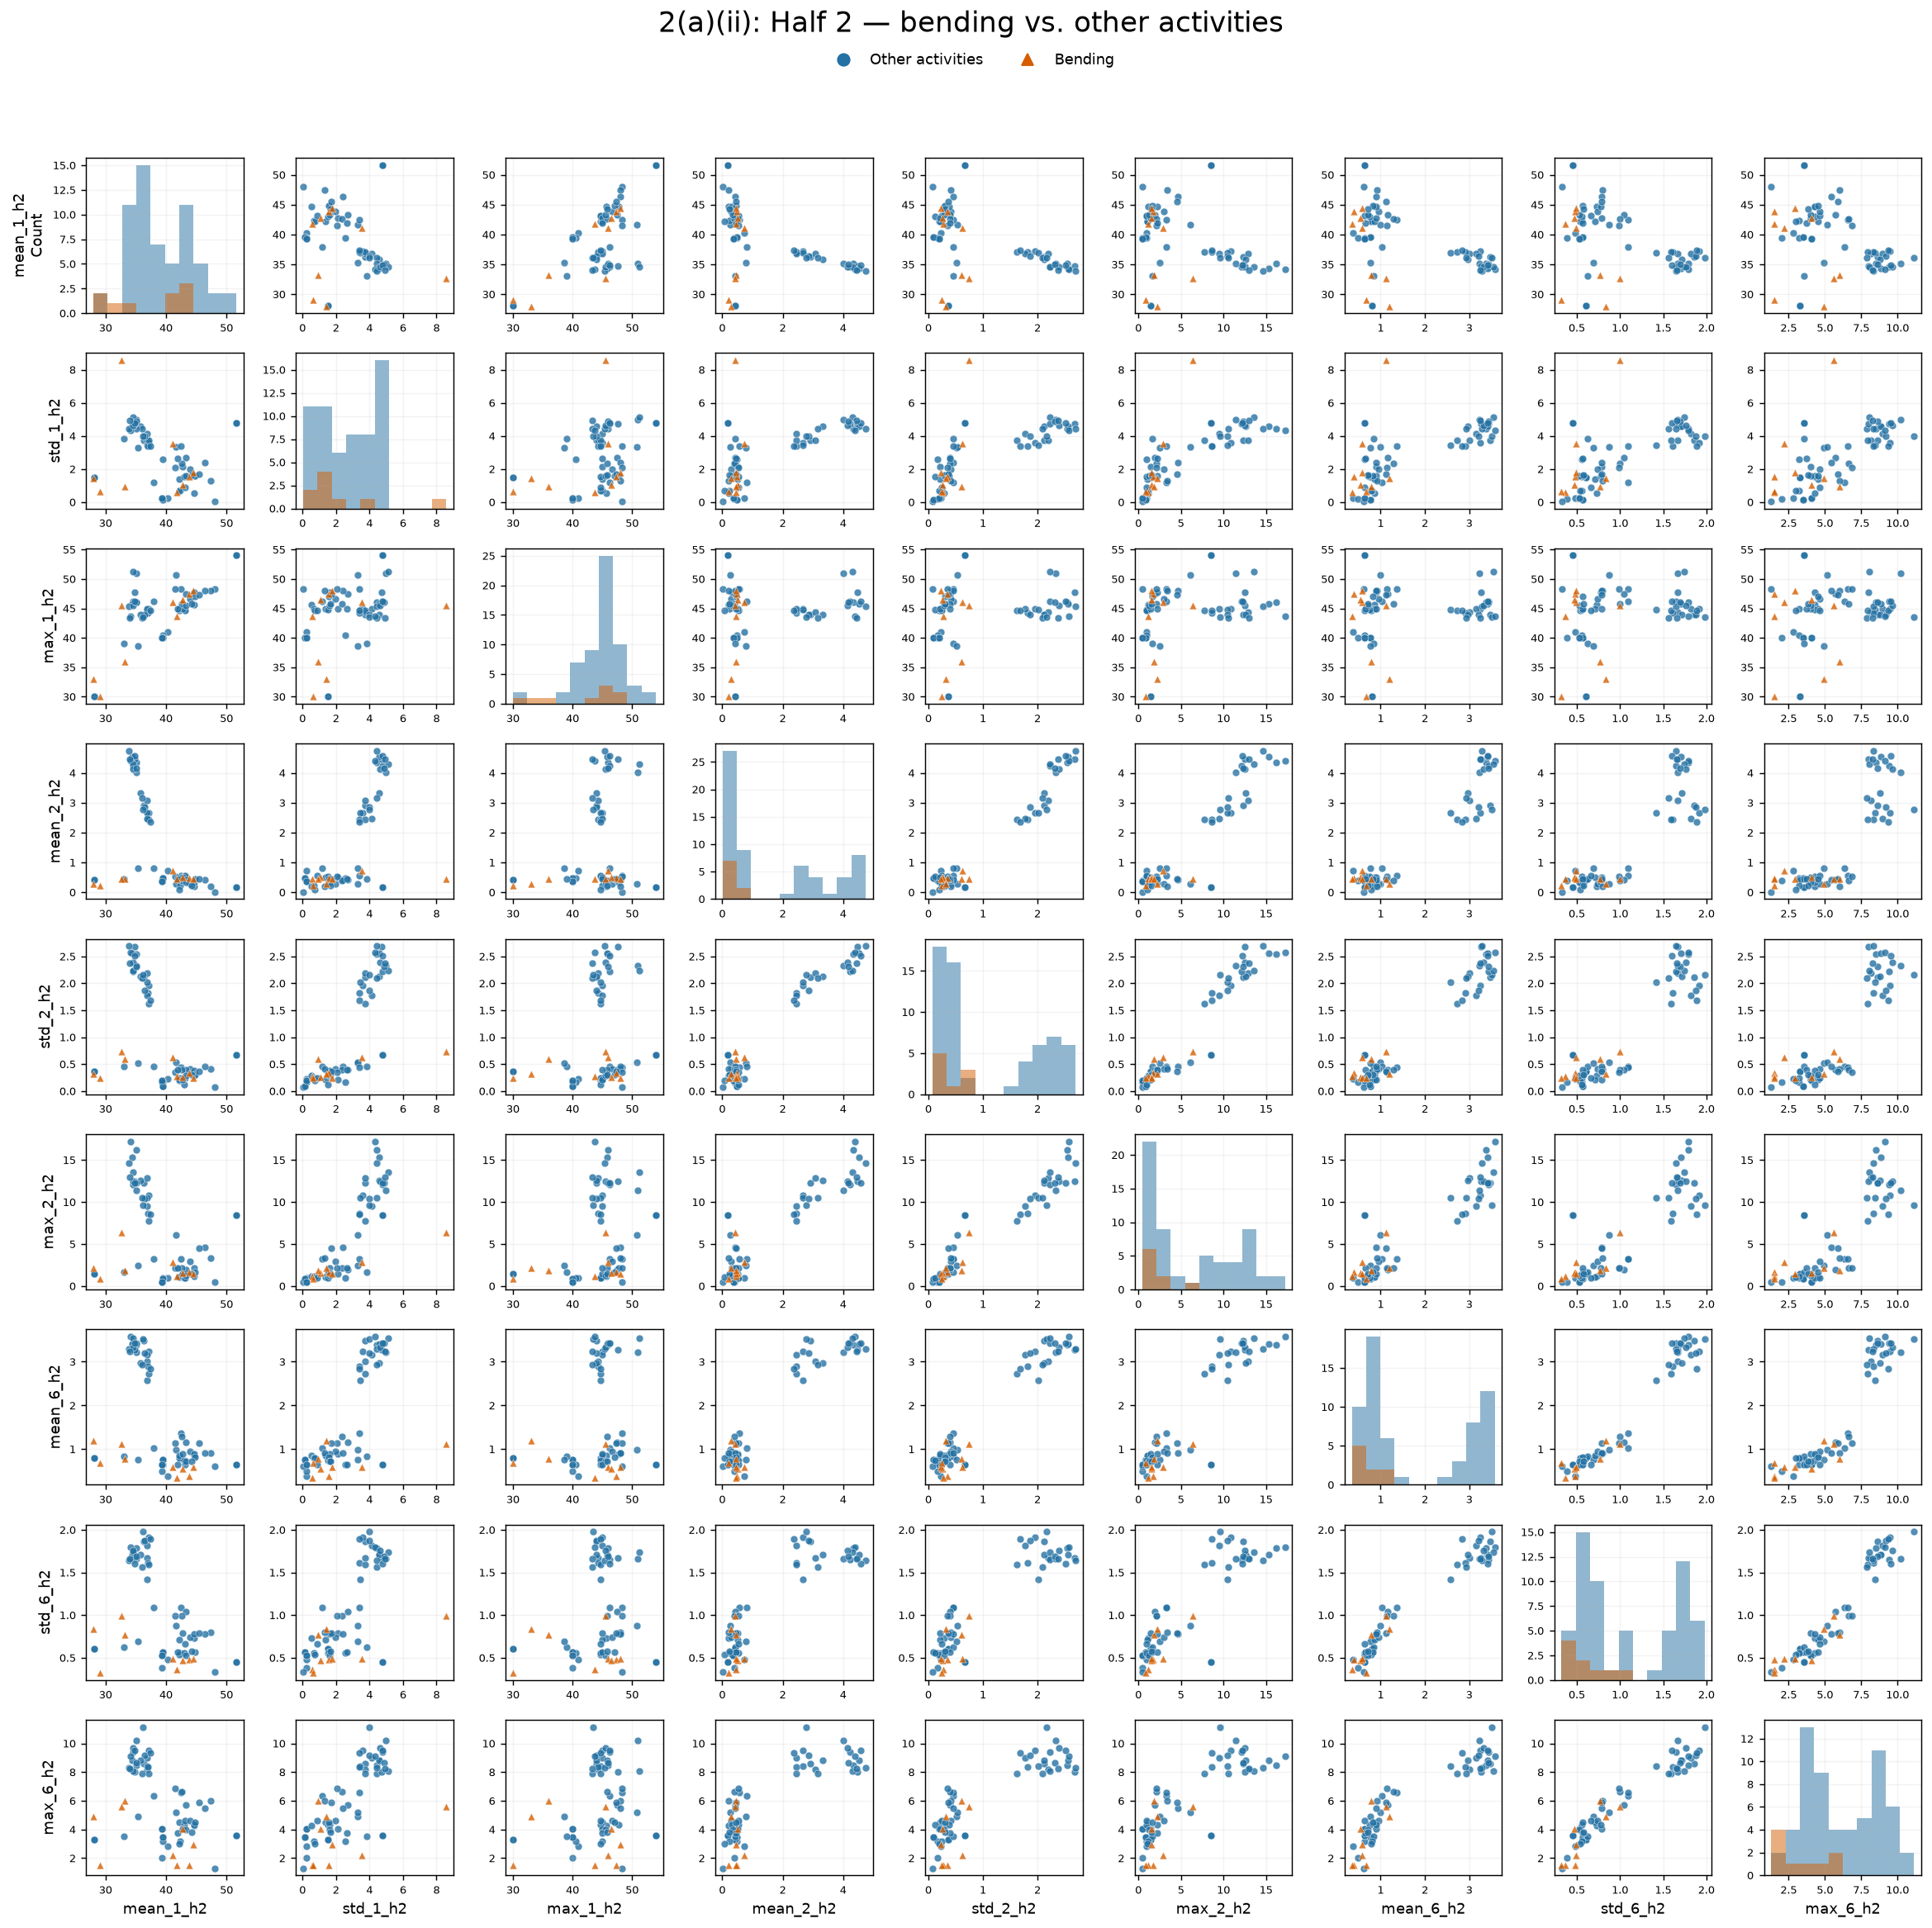

69 training instances: 9 bending and 60 other activities.
12 shorter series per instance; 18 selected features plotted.


In [ ]:
# Extract the same three statistics from both halves of all six series.
half_feature_rows = []
for source in train_files:
    row = {"activity": source.parent.name, "file": source.name}
    row["class"] = "Bending" if source.parent.name in {"bending1", "bending2"} else "Other activities"
    for series_number, values in enumerate(read_time_series(source), start=1):
        midpoint = len(values) // 2
        halves = (values[:midpoint], values[midpoint:])
        assert sum(map(len, halves)) == len(values)
        assert abs(len(halves[0]) - len(halves[1])) <= 1
        for half_number, half in enumerate(halves, start=1):
            row[f"mean_{series_number}_h{half_number}"] = mean(half)
            row[f"std_{series_number}_h{half_number}"] = stdev(half)
            row[f"max_{series_number}_h{half_number}"] = max(half)
    half_feature_rows.append(row)

half_plot_features = [f"{statistic}_{series}_h{half}"
                      for half in (1, 2)
                      for series in (1, 2, 6)
                      for statistic in ("mean", "std", "max")]
assert len(half_feature_rows) == 69
assert sum(row["class"] == "Bending" for row in half_feature_rows) == 9
assert len(half_plot_features) == 18
assert all(math.isfinite(row[feature])
           for row in half_feature_rows for feature in half_plot_features)

with (processed_root / "train_features_two_halves.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(half_feature_rows[0]))
    writer.writeheader()
    writer.writerows(half_feature_rows)

def plot_half_feature_matrix(columns, title, filename):
    count = len(columns)
    fig, axes = plt.subplots(count, count, figsize=(2 * count, 2 * count))
    for i, y_feature in enumerate(columns):
        for j, x_feature in enumerate(columns):
            ax = axes[i, j]
            all_x = [row[x_feature] for row in half_feature_rows]
            lo, hi = min(all_x), max(all_x)
            if lo == hi:
                lo, hi = lo - 0.5, hi + 0.5
            bins = [lo + (hi - lo) * k / 10 for k in range(11)]
            for label, style in styles.items():
                rows = [row for row in half_feature_rows if row["class"] == label]
                x = [row[x_feature] for row in rows]
                if i == j:
                    ax.hist(x, bins=bins, color=style["color"], alpha=0.5)
                else:
                    ax.scatter(x, [row[y_feature] for row in rows],
                               s=24, alpha=0.8, edgecolors="white", linewidths=0.3,
                               **style)
            if i == count - 1:
                ax.set_xlabel(x_feature, fontsize=10)
            if j == 0:
                ax.set_ylabel(y_feature if i != j else f"{y_feature}\nCount", fontsize=10)
            ax.tick_params(labelsize=7)
            ax.grid(alpha=0.15)
    fig.suptitle(title, fontsize=19, y=0.995)
    handles = [Line2D([], [], linestyle="", markersize=8, label=label,
                      color=style["color"], marker=style["marker"])
               for label, style in styles.items()]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.98),
               ncol=2, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(figure_root / filename, dpi=130, bbox_inches="tight")
    return fig

for half in (1, 2):
    columns = [feature for feature in half_plot_features if feature.endswith(f"_h{half}")]
    fig = plot_half_feature_matrix(
        columns, f"2(a)(ii): Half {half} — bending vs. other activities",
        f"2a_ii_half{half}_scatter_matrix.png")
    plt.show()
    plt.close(fig)

# Include every feature pair, including pairs from different halves.
fig = plot_half_feature_matrix(
    half_plot_features, "2(a)(ii): Both halves — all 18 selected features",
    "2a_ii_full_scatter_matrix.png")
plt.close(fig)
print("69 training instances: 9 bending and 60 other activities.")
print("12 shorter series per instance; 18 selected features plotted.")


[Full scatterplot matrix for all 18 features](../figures/2a_ii_full_scatter_matrix.png)

I do not see a considerable difference compared with part (i). Bending still tends to have low mean and standard deviation values in series 2 and 6, but some of the other activities have similar values. There is still overlap between the two groups in both halves.

Some points do move when I split the series. For example, one bending instance has a higher maximum in series 6 in the first half than in the second half. Using the whole series in part (i) did not show this difference. Overall, splitting gives more information about what happens during each instance, but the plots do not show a clear improvement in separating bending from the other activities.


#### (iii) Choosing the Number of Segments and Features with Cross-Validation

I used the RFE option from the question and adapted the professor's code. RFE fits a model, removes the feature with the smallest squared coefficient, and repeats this until it reaches the chosen number of features. I used `RFECV` to compare the feature counts with cross-validation, then used `RFE` to fit the final model and print `support_` and `ranking_`, like the professor's example. I used `n_features_to_select=p` because the current version of scikit-learn requires this argument to be named.

For each value of $l$ from 1 to 20, I split each of the six original series into $l$ consecutive segments of approximately equal length. I used all seven statistics from 1(c)(ii): minimum, maximum, mean, median, sample standard deviation, and the first and third quartiles. This gives $42l$ candidate features, but still only **69 training instances**. The restriction to series 1, 2, and 6 in the earlier parts was for the scatter plots; here I used all six series for classification.

I set bending1 and bending2 to 1 and the other activities to 0. I used **unregularized logistic regression** with `C=np.inf`, so there is no L2 penalty, as required by the footnote. I standardized the features inside the fitting process because RFE compares coefficient sizes. I used RFE instead of the p-value pruning option, so I did not calculate p-values for these models.

**Cross-validation:** I used `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. Stratification keeps roughly the same class proportions in each fold. With 9 bending instances, each validation fold gets either 1 or 2 bending instances and 12 other instances. I used the same folds for every value of $l$ and selected the pair $(l,p)$ with the highest mean **balanced accuracy**, which averages the recall for the two classes. A classifier that always predicts the other activities would get about 87% ordinary accuracy but only 50% balanced accuracy. For tied scores, I chose fewer features first, then the smaller $l$.

**The right way:** Split the original instances into folds first. In each fold, fit the scaler, run RFE, and fit logistic regression using only the four training folds. Then score the model on the remaining fold. I put the scaler and logistic regression in the estimator passed to `RFECV`, so they are fitted again for each training fold and feature subset. Extracting segment statistics before cross-validation is fine here because each row is calculated independently, without labels or information from other instances.

**The wrong way:** Run RFE or p-value selection on all 69 training instances and then cross-validate using that already selected feature set. The validation labels would have influenced feature selection, making the scores too optimistic. Fitting the scaler on all instances would also leak validation information. Splitting segments from one recording into separate rows and placing them in different folds would be wrong too; the segments belong to the same instance. I kept the 19 test instances out of this entire search.


In [ ]:
import json
import time
import warnings
import numpy as np
import sklearn
from sklearn.feature_selection import RFE, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
from joblib import parallel_config
from threadpoolctl import threadpool_limits

# Read only training recordings. The row order stays the same for every l.
training_series = [np.asarray(read_time_series(path), dtype=float).T
                   for path in train_files]
y_binary = np.array([int(path.parent.name in {"bending1", "bending2"})
                     for path in train_files])
assert len(training_series) == 69
assert np.bincount(y_binary).tolist() == [60, 9]

def extract_segment_features(recordings, l):
    statistic_names = ("min", "max", "mean", "median", "std", "q1", "q3")
    names = [f"{statistic}_{series}_seg{segment}"
             for segment in range(1, l + 1)
             for series in range(1, 7)
             for statistic in statistic_names]
    rows = []
    for recording in recordings:
        segments = np.array_split(recording, l, axis=0)
        assert sum(len(segment) for segment in segments) == len(recording)
        assert max(map(len, segments)) - min(map(len, segments)) <= 1
        values = []
        for segment in segments:
            # Each column is one original sensor series.
            statistics = np.stack([
                segment.min(axis=0), segment.max(axis=0),
                segment.mean(axis=0), np.median(segment, axis=0),
                segment.std(axis=0, ddof=1),
                np.quantile(segment, 0.25, axis=0, method="linear"),
                np.quantile(segment, 0.75, axis=0, method="linear"),
            ], axis=1)
            values.extend(statistics.ravel())
        rows.append(values)
    X = np.asarray(rows)
    assert X.shape == (len(recordings), 42 * l) and np.isfinite(X).all()
    return X, names

features_by_l = {}
feature_names_by_l = {}
for l in range(1, 21):
    features_by_l[l], feature_names_by_l[l] = extract_segment_features(training_series, l)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_splits = list(cv.split(np.zeros((69, 1)), y_binary))
print("Validation fold counts (other activities, bending):")
for fold, (training_indices, validation_indices) in enumerate(cv_splits, start=1):
    assert set(training_indices).isdisjoint(validation_indices)
    counts = np.bincount(y_binary[validation_indices], minlength=2)
    assert counts.min() > 0
    print(f"Fold {fold}: {tuple(int(count) for count in counts)}")

# Adapted from the professor's LogisticRegression + RFE example.
model = Pipeline([
    ("scale", StandardScaler()),
    ("logit", LogisticRegression(C=np.inf, solver="lbfgs", max_iter=5000, tol=1e-4)),
])
importance_path = "named_steps.logit.coef_"
print(f"scikit-learn version: {sklearn.__version__}")


Validation fold counts (other activities, bending):
Fold 1: (12, 2)
Fold 2: (12, 2)
Fold 3: (12, 2)
Fold 4: (12, 2)
Fold 5: (12, 1)
scikit-learn version: 1.9.1


In [ ]:
# RFECV uses the professor's backward-elimination approach inside each fold.
# step=1 checks every integer p from 1 through 42*l.
cv_rows = []
best_by_l = []
search_started = time.perf_counter()
with threadpool_limits(limits=1), parallel_config(backend="loky", inner_max_num_threads=1):
    for l in range(1, 21):
        selector = RFECV(
            estimator=model, step=1, min_features_to_select=1,
            cv=cv_splits, scoring="balanced_accuracy", n_jobs=5,
            importance_getter=importance_path,
        )
        selector.fit(features_by_l[l], y_binary)
        results = selector.cv_results_
        assert np.array_equal(results["n_features"], np.arange(1, 42 * l + 1))
        scores = results["mean_test_score"]
        # The counts are sorted, so the first maximum uses the fewest features.
        best_index = np.flatnonzero(np.isclose(scores, scores.max(), rtol=0, atol=1e-12))[0]
        best_by_l.append({
            "l": l, "candidate_features": 42 * l,
            "p": int(results["n_features"][best_index]),
            "mean_cv_balanced_accuracy": float(scores[best_index]),
            "std_cv_balanced_accuracy": float(results["std_test_score"][best_index]),
        })
        for index, p in enumerate(results["n_features"]):
            row = {"l": l, "p": int(p),
                   "mean_cv_balanced_accuracy": float(scores[index]),
                   "std_cv_balanced_accuracy": float(results["std_test_score"][index])}
            row.update({f"fold_{fold + 1}": float(results[f"split{fold}_test_score"][index])
                        for fold in range(5)})
            cv_rows.append(row)
        print(f"l={l:2d}, candidates={42*l:3d}, best p={best_by_l[-1]['p']:3d}, "
              f"mean balanced accuracy={scores[best_index]:.4f}", flush=True)

highest_score = max(row["mean_cv_balanced_accuracy"] for row in best_by_l)
tied_rows = [row for row in best_by_l
             if np.isclose(row["mean_cv_balanced_accuracy"], highest_score, rtol=0, atol=1e-12)]
best_result = min(tied_rows, key=lambda row: (row["p"], row["l"]))
best_l, best_p = best_result["l"], best_result["p"]
assert len(cv_rows) == sum(42 * l for l in range(1, 21)) == 8820

for filename, rows in (("2a_iii_cv_results.csv", cv_rows),
                       ("2a_iii_best_by_l.csv", best_by_l)):
    with (processed_root / filename).open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
print(f"Compared {len(cv_rows):,} (l, p) pairs in {(time.perf_counter()-search_started)/60:.1f} minutes.")
print(f"Selected pair: (l, p) = ({best_l}, {best_p})")


l= 1, candidates= 42, best p= 10, mean balanced accuracy=0.9917
l= 2, candidates= 84, best p=  7, mean balanced accuracy=0.9417
l= 3, candidates=126, best p= 10, mean balanced accuracy=0.9250
l= 4, candidates=168, best p= 15, mean balanced accuracy=0.9333
l= 5, candidates=210, best p= 23, mean balanced accuracy=0.9250
l= 6, candidates=252, best p= 41, mean balanced accuracy=0.9833
l= 7, candidates=294, best p= 32, mean balanced accuracy=0.9250
l= 8, candidates=336, best p=270, mean balanced accuracy=0.9250
l= 9, candidates=378, best p= 69, mean balanced accuracy=0.9167
l=10, candidates=420, best p= 18, mean balanced accuracy=0.9917
l=11, candidates=462, best p=  4, mean balanced accuracy=0.9417
l=12, candidates=504, best p= 25, mean balanced accuracy=0.9750
l=13, candidates=546, best p=  7, mean balanced accuracy=0.9750
l=14, candidates=588, best p= 60, mean balanced accuracy=0.9500
l=15, candidates=630, best p= 34, mean balanced accuracy=0.9667
l=16, candidates=672, best p= 15, mean b

In [ ]:
# Refit on all 69 training instances using the chosen l and p.
# These lines follow the professor's snippet, with the current RFE syntax.
rfe = RFE(estimator=model, n_features_to_select=best_p, step=1,
          importance_getter=importance_path)
with warnings.catch_warnings(record=True) as refit_warnings, threadpool_limits(limits=1):
    warnings.simplefilter("always", ConvergenceWarning)
    rfe = rfe.fit(features_by_l[best_l], y_binary)
final_logit = rfe.estimator_.named_steps["logit"]
convergence_warning_count = sum(issubclass(w.category, ConvergenceWarning) for w in refit_warnings)
assert np.isfinite(final_logit.coef_).all() and np.isfinite(final_logit.intercept_).all()
print(f"Final logistic fit: {final_logit.n_iter_[0]} iterations (cap: {final_logit.max_iter}).")
print(f"Convergence warnings during final RFE refit: {convergence_warning_count}")
print("Finite final coefficients: True")
print("Selected feature mask (rfe.support_):")
print(rfe.support_)
print("Feature rankings (rfe.ranking_):")
print(rfe.ranking_)

selected_names = np.array(feature_names_by_l[best_l])[rfe.support_].tolist()
assert len(selected_names) == best_p
print("Selected features:", selected_names)

# Show ordinary accuracy as well, using fold-specific scaling and RFE again.
# These are tuning-fold diagnostics for the chosen pair, not an independent test.
with threadpool_limits(limits=1):
    chosen_cv = cross_validate(
        rfe, features_by_l[best_l], y_binary, cv=cv_splits,
        scoring={"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"},
        error_score="raise",
    )
assert np.isclose(chosen_cv["test_balanced_accuracy"].mean(), highest_score)
print("Chosen-pair fold balanced accuracies:", chosen_cv["test_balanced_accuracy"])
print(f"Mean CV balanced accuracy: {chosen_cv['test_balanced_accuracy'].mean():.4f}")
print(f"Mean CV ordinary accuracy: {chosen_cv['test_accuracy'].mean():.4f}")

ranking_rows = [{"feature": name, "selected": bool(selected), "rank": int(rank)}
                for name, selected, rank in zip(feature_names_by_l[best_l], rfe.support_, rfe.ranking_)]
with (processed_root / "2a_iii_feature_ranking.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(ranking_rows[0]))
    writer.writeheader()
    writer.writerows(ranking_rows)
summary_2a_iii = {
    "best_l": best_l, "best_p": best_p, "scoring": "balanced_accuracy",
    "mean_cv_balanced_accuracy": float(chosen_cv["test_balanced_accuracy"].mean()),
    "mean_cv_accuracy": float(chosen_cv["test_accuracy"].mean()),
    "fold_balanced_accuracy": chosen_cv["test_balanced_accuracy"].tolist(),
    "fold_accuracy": chosen_cv["test_accuracy"].tolist(),
    "selected_features": selected_names, "candidate_pairs": len(cv_rows),
    "sklearn_version": sklearn.__version__, "C": "infinity (unregularized)",
    "seed": 42, "training_instances": 69,
}
(processed_root / "2a_iii_summary.json").write_text(json.dumps(summary_2a_iii, indent=2) + "\n")


Final logistic fit: 14 iterations (cap: 5000).
Convergence warnings during final RFE refit: 0
Finite final coefficients: True
Selected feature mask (rfe.support_):
[ True False False False False False  True False  True False False False
 False False False False False False False False  True False  True False
 False False  True False  True  True  True False False False False False
 False False False False  True False]
Feature rankings (rfe.ranking_):
[ 1  2  4 14 24 23  1 33  1 30 16 18 31 21 27  7 19 12  9 29  1 32  1 17
  6 28  1 22  1  1  1 15 25  5 10 20 26 11  8  3  1 13]
Selected features: ['min_1_seg1', 'q3_1_seg1', 'max_2_seg1', 'q3_3_seg1', 'max_4_seg1', 'q1_4_seg1', 'min_5_seg1', 'max_5_seg1', 'mean_5_seg1', 'q1_6_seg1']
Chosen-pair fold balanced accuracies: [0.95833333 1.         1.         1.         1.        ]
Mean CV balanced accuracy: 0.9917
Mean CV ordinary accuracy: 0.9857


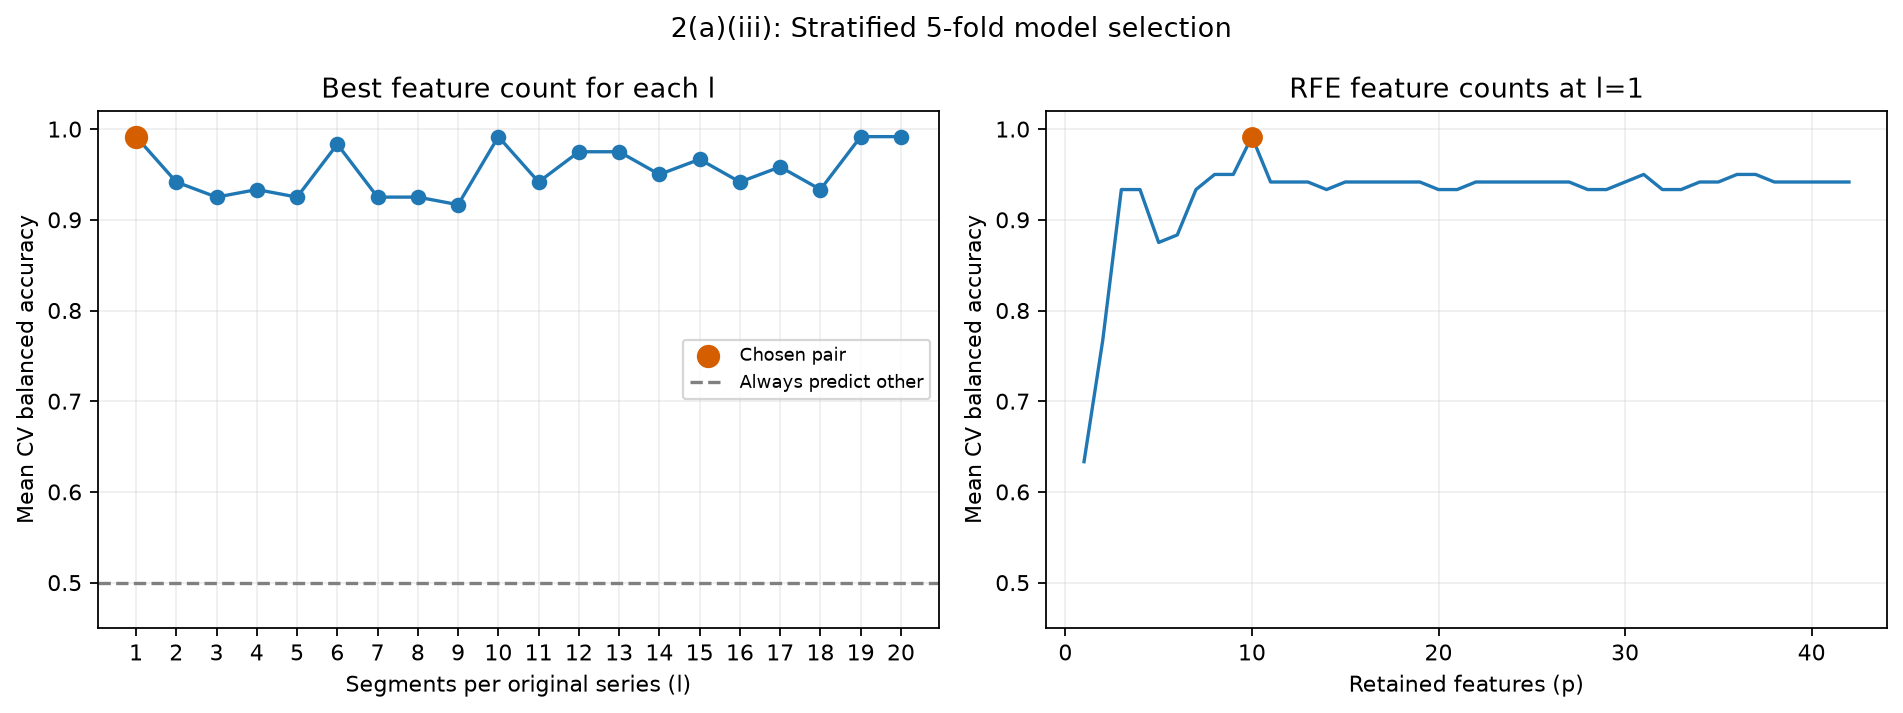

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ls = [row["l"] for row in best_by_l]
axes[0].plot(ls, [row["mean_cv_balanced_accuracy"] for row in best_by_l], marker="o")
axes[0].scatter([best_l], [highest_score], color="#D55E00", s=90, zorder=3, label="Chosen pair")
axes[0].axhline(0.5, color="gray", linestyle="--", label="Always predict other")
axes[0].set(xlabel="Segments per original series (l)", ylabel="Mean CV balanced accuracy",
            title="Best feature count for each l", xticks=range(1, 21), ylim=(0.45, 1.02))
axes[0].legend(fontsize=8)
selected_l_rows = [row for row in cv_rows if row["l"] == best_l]
axes[1].plot([row["p"] for row in selected_l_rows],
             [row["mean_cv_balanced_accuracy"] for row in selected_l_rows])
axes[1].scatter([best_p], [highest_score], color="#D55E00", s=70, zorder=3)
axes[1].set(xlabel="Retained features (p)", ylabel="Mean CV balanced accuracy",
            title=f"RFE feature counts at l={best_l}", ylim=(0.45, 1.02))
for ax in axes:
    ax.grid(alpha=0.2)
fig.suptitle("2(a)(iii): Stratified 5-fold model selection")
fig.tight_layout()
fig.savefig(figure_root / "2a_iii_model_selection.png", dpi=160, bbox_inches="tight")
plt.show()


**My result:** The best pair was **$(l,p)=(1,10)$**, with a mean 5-fold balanced accuracy of **99.17%** and a mean ordinary accuracy of **98.57%**. The fold balanced accuracies were 95.83%, 100%, 100%, 100%, and 100%. Some larger values of $l$ reached the same mean balanced accuracy, but none did better. I chose $l=1$ using my tie rule, so splitting the series into more segments was not needed for the best result in this search.

After choosing the pair, I ran RFE again on all 69 training instances and fitted logistic regression using the 10 selected features. Since $l=1$, these features describe the whole recording: `min_1`, `q3_1`, `max_2`, `q3_3`, `max_4`, `q1_4`, `min_5`, `max_5`, `mean_5`, and `q1_6`. In the code output, `_seg1` indicates the single segment. A value of `True` in `support_` means that RFE kept the feature, and a rank of 1 in `ranking_` means it was selected.

These CV scores were used to choose the model, so I would not treat them as an independent estimate of its final accuracy. There are also only 9 bending instances, so each fold has very few bending examples. I kept the test set untouched for the later evaluation.

I also checked the final model because of the warning about instability in footnote 5. It stopped after 14 iterations, even though I set `max_iter=5000`. The final coefficients were finite, and there were no convergence warnings during the RFE refit, so I kept the same setting. If the fitting becomes unstable because the classes are linearly separable, I would lower `max_iter` to stop it earlier and rerun cross-validation, as the professor suggests. Increasing the limit would not fix that problem. Even if the solver stops without a warning, the coefficients can still be unreliable when the classes are perfectly separable.

For footnote 6, I used RFE instead of selecting features with p-values. This follows the alternative given in the question and the professor's example, so I did not need to calculate p-values or use R. These checks did not change my selected pair or the CV scores.

I referred to the scikit-learn documentation for [RFE](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html), [stratified folds](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html), [unregularized logistic regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), and [avoiding data leakage during feature selection](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).


#### (iv) Training Confusion Matrix, ROC, AUC, and Model Parameters

I used the model I chose in part (iii), with **$l=1$ and $p=10$**, to predict the labels of the 69 training instances. Bending is class 1, and the other activities are class 0. I used a cutoff of 0.5 for the confusion matrix. For the ROC curve, I used the predicted probabilities instead of the class labels.


Class order: 0 = other activities, 1 = bending
Confusion matrix (rows = actual, columns = predicted):
[[60  0]
 [ 0  9]]
Training accuracy: 1.0000
Training ROC AUC: 1.0000


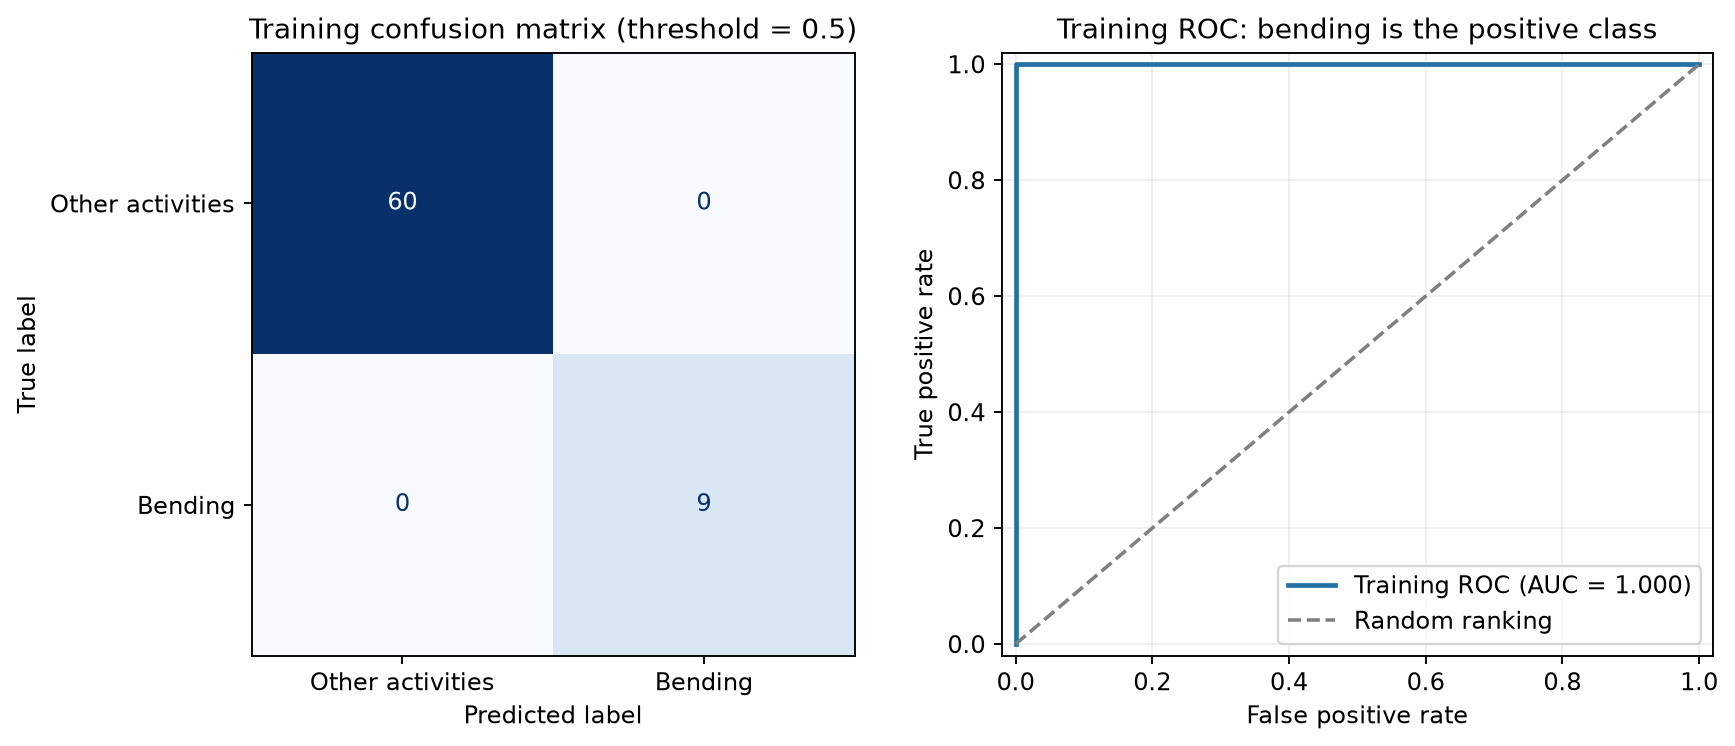

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, accuracy_score

X_selected_l = features_by_l[best_l]
positive_column = list(rfe.classes_).index(1)
train_probabilities = rfe.predict_proba(X_selected_l)[:, positive_column]
train_predictions = (train_probabilities >= 0.5).astype(int)
train_confusion = confusion_matrix(y_binary, train_predictions, labels=[0, 1])
train_accuracy = accuracy_score(y_binary, train_predictions)
train_auc = roc_auc_score(y_binary, train_probabilities)
fpr, tpr, thresholds = roc_curve(y_binary, train_probabilities, pos_label=1)
assert train_confusion.sum() == 69
assert np.array_equal(train_predictions, rfe.predict(X_selected_l))

print("Class order: 0 = other activities, 1 = bending")
print("Confusion matrix (rows = actual, columns = predicted):")
print(train_confusion)
print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Training ROC AUC: {train_auc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.5))
ConfusionMatrixDisplay(train_confusion, display_labels=["Other activities", "Bending"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Training confusion matrix (threshold = 0.5)")
axes[1].plot(fpr, tpr, color="#2471A3", linewidth=2,
             label=f"Training ROC (AUC = {train_auc:.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate",
            title="Training ROC: bending is the positive class",
            xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.2)
fig.tight_layout()
fig.savefig(figure_root / "2a_iv_training_evaluation.png", dpi=170, bbox_inches="tight")
plt.show()

prediction_rows = [{"activity": path.parent.name, "file": path.name,
                    "actual_bending": int(actual), "predicted_bending": int(prediction),
                    "probability_bending": float(probability)}
                   for path, actual, prediction, probability in
                   zip(train_files, y_binary, train_predictions, train_probabilities)]
with (processed_root / "2a_iv_training_predictions.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(prediction_rows[0]))
    writer.writeheader()
    writer.writerows(prediction_rows)


The table below shows the intercept and the 10 coefficients. Since I standardized the features before fitting the model, the equation is

$$\log\left(\frac{P(\text{bending}\mid x)}{1-P(\text{bending}\mid x)}\right)
=\beta_0+\sum_{j=1}^{10}\beta_j z_j,\qquad z_j=\frac{x_j-\mu_j}{s_j}.$$

Here, $z_j$ is the standardized value of a feature. I also converted the coefficients and intercept back to the original units and included those values in the table.

I used RFE in part (iii), but this part also asks for p-values. I calculated the usual Wald values by dividing each coefficient by its estimated standard error and comparing it with the standard normal distribution. The code gets the standard errors from the inverse of $D^TWD$, where $D$ contains the features and intercept, and $W_{ii}=\hat p_i(1-\hat p_i)$.

However, the model completely separates the two classes in the training set. This makes the usual p-values unreliable. I included the numerical Wald values to show the calculation, but marked the valid MLE p-values as **N/A**. I would not use the numerical values to decide which features are significant.


In [ ]:
from scipy.special import expit
from scipy.stats import norm
from html import escape

final_pipeline = rfe.estimator_
final_scaler = final_pipeline.named_steps["scale"]
final_logit = final_pipeline.named_steps["logit"]
X_kept = rfe.transform(X_selected_l)
Z_kept = final_scaler.transform(X_kept)
design = np.column_stack([np.ones(len(Z_kept)), Z_kept])
beta_standardized = np.r_[final_logit.intercept_, final_logit.coef_.ravel()]
linear_scores = design @ beta_standardized
np.testing.assert_allclose(expit(linear_scores), train_probabilities, atol=1e-12)

# Strictly positive signed margins give a separating hyperplane.
signed_margins = (2 * y_binary - 1) * linear_scores
complete_separation = bool(np.all(signed_margins > 0))
print(f"Complete separation confirmed: {complete_separation}")
print(f"Smallest signed training margin: {signed_margins.min():.6f}")
print(f"Final logistic iterations: {final_logit.n_iter_[0]}")
# Under complete separation, making the coefficients larger keeps improving
# the likelihood, so there is no finite unregularized maximum-likelihood estimate.
nll_at_fit = float(np.logaddexp(0, -signed_margins).sum())
nll_at_double = float(np.logaddexp(0, -2 * signed_margins).sum())
print(f"Negative log-likelihood at fitted beta: {nll_at_fit:.8f}")
print(f"Negative log-likelihood at 2*beta: {nll_at_double:.8f}")

# Convert both the coefficients and the covariance to the original units.
conversion = np.eye(best_p + 1)
conversion[0, 1:] = -final_scaler.mean_ / final_scaler.scale_
conversion[1:, 1:] = np.diag(1 / final_scaler.scale_)
beta_original = conversion @ beta_standardized
np.testing.assert_allclose(
    np.column_stack([np.ones(len(X_kept)), X_kept]) @ beta_original,
    linear_scores, rtol=1e-10, atol=1e-10)

# Compute the usual Wald formula at the stopped fit for transparency.
# These numbers must NOT be used as valid p-values under complete separation.
weights = expit(linear_scores) * expit(-linear_scores)
information = design.T @ (design * weights[:, None])
information_rank = int(np.linalg.matrix_rank(information))
information_condition = float(np.linalg.cond(information))
nominal_p_values = np.full(best_p + 1, np.nan)
nominal_standard_errors = np.full(best_p + 1, np.nan)
if information_rank == best_p + 1 and information_condition < 1e12:
    covariance_standardized = np.linalg.solve(information, np.eye(best_p + 1))
    covariance_original = conversion @ covariance_standardized @ conversion.T
    nominal_standard_errors = np.sqrt(np.diag(covariance_original))
    nominal_p_values = 2 * norm.sf(np.abs(beta_original / nominal_standard_errors))

parameter_names = ["Intercept"] + np.array(feature_names_by_l[best_l])[rfe.support_].tolist()
parameter_rows = []
for name, standardized, original, nominal_se, nominal_p in zip(
        parameter_names, beta_standardized, beta_original, nominal_standard_errors, nominal_p_values):
    parameter_rows.append({
        "parameter": name, "beta_standardized": float(standardized),
        "beta_original_units": float(original),
        "nominal_se_original_units": float(nominal_se),
        "nominal_Wald_p_at_stopped_fit": float(nominal_p),
        "valid_MLE_p_value": "N/A" if complete_separation else "not assessed",
        "inference_note": "Complete separation; nominal Wald p is not valid" if complete_separation
                          else "Feature selection on the same data also affects inference",
    })

headers = ["Parameter", "Standardized beta", "Original-unit beta",
           "Nominal Wald p*", "Valid MLE p-value"]
table = '<table><thead><tr>' + ''.join(f'<th>{header}</th>' for header in headers) + '</tr></thead><tbody>'
for row in parameter_rows:
    nominal = row["nominal_Wald_p_at_stopped_fit"]
    nominal_text = f"{nominal:.6f}" if np.isfinite(nominal) else "N/A"
    table += (f'<tr><td>{escape(row["parameter"])}</td>'
              f'<td>{row["beta_standardized"]:.6f}</td>'
              f'<td>{row["beta_original_units"]:.6f}</td>'
              f'<td>{nominal_text}</td><td>{row["valid_MLE_p_value"]}</td></tr>')
table += '</tbody></table><p>*Numerical Wald values at the stopped fit; unreliable under complete separation.</p>'
display(HTML(table))
with (processed_root / "2a_iv_coefficients.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(parameter_rows[0]))
    writer.writeheader()
    writer.writerows(parameter_rows)

evaluation_summary = {
    "l": best_l, "p": best_p, "training_instances": len(y_binary),
    "class_order": ["other activities", "bending"], "threshold": 0.5,
    "training_confusion_matrix": train_confusion.tolist(),
    "training_accuracy": float(train_accuracy), "training_auc": float(train_auc),
    "complete_separation": complete_separation,
    "minimum_signed_margin": float(signed_margins.min()),
    "n_iter": int(final_logit.n_iter_[0]),
    "information_rank": information_rank, "information_condition": information_condition,
    "p_value_status": "Conventional MLE p-values unavailable under complete separation",
}
(processed_root / "2a_iv_summary.json").write_text(json.dumps(evaluation_summary, indent=2) + "\n")


Complete separation confirmed: True
Smallest signed training margin: 7.003864
Final logistic iterations: 14
Negative log-likelihood at fitted beta: 0.00395688
Negative log-likelihood at 2*beta: 0.00000186


Parameter,Standardized beta,Original-unit beta,Nominal Wald p*,Valid MLE p-value
Intercept,-12.037936,-12.743667,0.951837,N/A
min_1_seg1,-2.431784,-0.278544,0.969379,N/A
q3_1_seg1,-2.455155,-0.516999,0.958335,N/A
max_2_seg1,-1.821774,-0.356484,0.972881,N/A
q3_3_seg1,-2.007406,-0.512443,0.950616,N/A
max_4_seg1,2.533163,1.108284,0.959959,N/A
q1_4_seg1,-3.058622,-3.655831,0.970955,N/A
min_5_seg1,5.105711,0.957966,0.933518,N/A
max_5_seg1,5.720230,1.057326,0.855084,N/A
mean_5_seg1,3.394528,0.667784,0.968024,N/A


My model correctly classified all **60 other-activity instances and all 9 bending instances** in the training set. There were no false positives or false negatives, so the training accuracy was **100%**. The ROC curve also gave an **AUC of 1.00**. Since I tested the model on the same data used to fit it, I would not expect this result to guarantee perfect performance on new data.

I also checked the separation issue mentioned in the professor's footnote. Every training instance was on the correct side of the decision boundary, and doubling the coefficients improved the likelihood even more. This means the unregularized fit does not have a finite maximum-likelihood estimate. The coefficients in my table are the values returned when the solver stopped after 14 iterations.

Stopping earlier keeps the reported coefficients finite, but it does not fix the p-value problem. This is why I reported the valid p-values as **N/A** and kept the numerical Wald values only for reference. I kept the same model from part (iii), without adding regularization. I referred to the [statsmodels explanation of separation and convergence](https://www.statsmodels.org/stable/pitfalls.html#incomplete-convergence-in-maximum-likelihood-estimation) for this issue.


#### (v) Testing the Classifier on the Test Set

I tested the model from part (iii) on the 19 test instances. The best value of $l$ was 1, so I kept each test series as one segment. I extracted the same features in the same order as the training data and used the 10 features that RFE had already selected.

I used the scaler and model fitted on the training set, without fitting them again on the test set. I also kept the same cutoff of 0.5 to predict bending or other activities.


In [ ]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix

test_series = [np.asarray(read_time_series(path), dtype=float).T for path in test_files]
y_test_binary = np.array([int(path.parent.name in {"bending1", "bending2"})
                          for path in test_files])
X_test_segments, test_feature_names = extract_segment_features(test_series, best_l)
assert len(test_files) == 19 and np.bincount(y_test_binary).tolist() == [15, 4]
assert set(train_files).isdisjoint(test_files)
assert test_feature_names == feature_names_by_l[best_l]
assert X_test_segments.shape == (19, 42 * best_l)

# predict_proba applies the existing RFE mask and training-fitted scaler.
# No fit or fit_transform is called on the test data.
coefficients_before_test = rfe.estimator_.named_steps["logit"].coef_.copy()
scaler_mean_before_test = rfe.estimator_.named_steps["scale"].mean_.copy()
test_probability = rfe.predict_proba(X_test_segments)[:, list(rfe.classes_).index(1)]
test_prediction = (test_probability >= 0.5).astype(int)
np.testing.assert_array_equal(rfe.estimator_.named_steps["logit"].coef_, coefficients_before_test)
np.testing.assert_array_equal(rfe.estimator_.named_steps["scale"].mean_, scaler_mean_before_test)

test_accuracy = accuracy_score(y_test_binary, test_prediction)
test_balanced_accuracy = balanced_accuracy_score(y_test_binary, test_prediction)
test_confusion = confusion_matrix(y_test_binary, test_prediction, labels=[0, 1])
cv_accuracy = float(np.mean(chosen_cv["test_accuracy"]))
cv_balanced_accuracy = float(np.mean(chosen_cv["test_balanced_accuracy"]))
correct_test = int(np.sum(y_test_binary == test_prediction))

print(f"Selected model: l={best_l}, p={best_p}")
print(f"Test instances: {len(y_test_binary)} (15 other activities, 4 bending)")
print(f"Test accuracy: {correct_test}/19 = {test_accuracy:.2%}")
print(f"Previous mean 5-fold CV accuracy: {cv_accuracy:.2%}")
print(f"Test minus CV accuracy: {(test_accuracy - cv_accuracy) * 100:+.2f} percentage points")
print(f"Test balanced accuracy: {test_balanced_accuracy:.2%}")
print(f"Previous mean 5-fold CV balanced accuracy: {cv_balanced_accuracy:.2%}")
print("Test confusion matrix (rows = actual, columns = predicted; order: other, bending):")
print(test_confusion)

test_prediction_rows = [{"activity": path.parent.name, "file": path.name,
                         "actual_bending": int(actual), "predicted_bending": int(prediction),
                         "probability_bending": float(probability)}
                        for path, actual, prediction, probability in
                        zip(test_files, y_test_binary, test_prediction, test_probability)]
with (processed_root / "2a_v_test_predictions.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(test_prediction_rows[0]))
    writer.writeheader()
    writer.writerows(test_prediction_rows)

test_summary = {
    "l": best_l, "p": best_p, "test_instances": len(y_test_binary),
    "test_correct": correct_test, "test_accuracy": float(test_accuracy),
    "mean_cv_accuracy": cv_accuracy,
    "test_minus_cv_accuracy_percentage_points": float(100 * (test_accuracy - cv_accuracy)),
    "test_balanced_accuracy": float(test_balanced_accuracy),
    "mean_cv_balanced_accuracy": cv_balanced_accuracy,
    "test_confusion_matrix": test_confusion.tolist(), "class_order": ["other activities", "bending"],
    "threshold": 0.5,
}
(processed_root / "2a_v_summary.json").write_text(json.dumps(test_summary, indent=2) + "\n")


Selected model: l=1, p=10
Test instances: 19 (15 other activities, 4 bending)
Test accuracy: 19/19 = 100.00%
Previous mean 5-fold CV accuracy: 98.57%
Test minus CV accuracy: +1.43 percentage points
Test balanced accuracy: 100.00%
Previous mean 5-fold CV balanced accuracy: 99.17%
Test confusion matrix (rows = actual, columns = predicted; order: other, bending):
[[15  0]
 [ 0  4]]


The model got all **19 test instances correct**, so the **test accuracy was 100%**. It correctly classified all 15 instances from the other activities and all 4 bending instances. In part (iii), the mean cross-validation accuracy was **98.57%**, so the test accuracy was 1.43 percentage points higher. The test balanced accuracy was also 100%, compared with 99.17% during cross-validation.

The test result is similar to the high accuracy I got in cross-validation. However, the test set only has 19 instances. Even one wrong prediction would lower the accuracy by about 5.26 percentage points, so I would not expect the model to always get every new instance correct. I used the model chosen from the training data without changing it based on these test results.


#### (vi) Separation and Instability in Logistic Regression

Yes, the two classes seem well-separated when I use the selected features together. The model got all 69 training instances correct and had a training AUC of 1.00. I also checked that every training point was on the correct side of the decision boundary. Some points overlapped in the earlier scatter plots, but those plots only compared two features at a time.

This separation can make the logistic regression coefficients unstable. When I doubled the coefficients, the likelihood still improved. This means the coefficients can keep getting larger instead of settling at finite maximum-likelihood estimates. Because of this, I would not trust the usual p-values for this fit.

The solver stopped after 14 iterations without a warning, but that does not mean the separation problem is gone. If the fitting becomes unstable, I can lower `max_iter` to stop it earlier, as the professor suggests. This can keep the reported coefficients from growing too large, but it does not fix the p-values.


#### (vii) Class Imbalance and Case-Control Sampling

Yes, the classes are imbalanced. From the confusion matrices, I have **60 other-activity and 9 bending instances** in training, and **15 other-activity and 4 bending instances** in testing. Even though my original model got every prediction correct, there are still many more instances from the other activities than from bending.

I used case-control sampling to make a balanced training sample. I kept all 9 bending instances and randomly picked 9 other-activity instances without replacement, using seed 42. I then fitted a new scaler and logistic regression model on these 18 instances, using the same 10 features and $l=1$ from part (iii). I kept regularization off and did not use the test set to fit the model.

Bending makes up half of this new sample, but it only makes up $9/69$ of the original training set. To account for this difference, I adjusted the intercept using

$$\beta_{0,\mathrm{adjusted}}=\beta_{0,\mathrm{sample}}
++\log\left(\frac{\pi}{1-\pi}\right)
+-\log\left(\frac{\pi_s}{1-\pi_s}\right),$$

where $\pi=9/69$ and $\pi_s=0.5$. This means I added $\log(9/60)\approx-1.8971$ to the intercept. I left the slope coefficients unchanged. I used the original training proportion for this adjustment because I do not know the class proportion for future data. I referred to [Fithian and Hastie's explanation of case-control sampling](https://arxiv.org/html/1306.3706v2#S2) for the correction.


In [ ]:
from copy import deepcopy
from sklearn.base import clone
from scipy.special import expit, logit
from sklearn.metrics import confusion_matrix, accuracy_score, balanced_accuracy_score, roc_curve, roc_auc_score, ConfusionMatrixDisplay

case_indices = np.flatnonzero(y_binary == 1)
control_indices = np.flatnonzero(y_binary == 0)
case_control_rng = np.random.default_rng(42)
sampled_control_indices = case_control_rng.choice(control_indices, size=len(case_indices), replace=False)
case_control_indices = np.sort(np.r_[case_indices, sampled_control_indices])
y_case_control = y_binary[case_control_indices]
assert np.bincount(y_case_control).tolist() == [9, 9]
assert len(np.unique(case_control_indices)) == 18

X_train_case_features = rfe.transform(features_by_l[best_l])
X_test_case_features = rfe.transform(X_test_segments)
sampled_model = clone(model)
with warnings.catch_warnings(record=True) as case_control_warnings, threadpool_limits(limits=1):
    warnings.simplefilter("always", ConvergenceWarning)
    sampled_model.fit(X_train_case_features[case_control_indices], y_case_control)

target_prior = float(y_binary.mean())
sample_prior = float(y_case_control.mean())
intercept_adjustment = float(logit(target_prior) - logit(sample_prior))
adjusted_case_control_model = deepcopy(sampled_model)
sampled_intercept = float(sampled_model.named_steps["logit"].intercept_[0])
adjusted_case_control_model.named_steps["logit"].intercept_ += intercept_adjustment
adjusted_intercept = float(adjusted_case_control_model.named_steps["logit"].intercept_[0])
np.testing.assert_array_equal(sampled_model.named_steps["logit"].coef_,
                              adjusted_case_control_model.named_steps["logit"].coef_)
assert np.isclose(intercept_adjustment, np.log(9 / 60))
print("Original training counts (other, bending):", np.bincount(y_binary))
print("Case-control sample counts (other, bending):", np.bincount(y_case_control))
print(f"Target bending proportion: {target_prior:.6f}; sample proportion: {sample_prior:.6f}")
print(f"Sample-fitted standardized intercept: {sampled_intercept:.6f}")
print(f"Intercept adjustment: {intercept_adjustment:.6f}")
print(f"Adjusted standardized intercept: {adjusted_intercept:.6f}")
print(f"Final logistic iterations: {sampled_model.named_steps['logit'].n_iter_[0]}")
print("Convergence warnings:", sum(issubclass(w.category, ConvergenceWarning) for w in case_control_warnings))

sample_rows = [{"activity": train_files[index].parent.name, "file": train_files[index].name,
                "bending": int(y_binary[index])} for index in case_control_indices]
with (processed_root / "2a_vii_case_control_sample.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(sample_rows[0]))
    writer.writeheader()
    writer.writerows(sample_rows)

case_parameter_names = ["Intercept"] + np.array(feature_names_by_l[best_l])[rfe.support_].tolist()
sample_parameters = np.r_[sampled_intercept, sampled_model.named_steps["logit"].coef_.ravel()]
adjusted_parameters = np.r_[adjusted_intercept, adjusted_case_control_model.named_steps["logit"].coef_.ravel()]
case_parameter_rows = [{"parameter": name, "sample_standardized_beta": float(before),
                        "adjusted_standardized_beta": float(after)}
                       for name, before, after in zip(case_parameter_names, sample_parameters, adjusted_parameters)]
with (processed_root / "2a_vii_case_control_parameters.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(case_parameter_rows[0]))
    writer.writeheader()
    writer.writerows(case_parameter_rows)


Original training counts (other, bending): [60  9]
Case-control sample counts (other, bending): [9 9]
Target bending proportion: 0.130435; sample proportion: 0.500000
Sample-fitted standardized intercept: 0.763516
Intercept adjustment: -1.897120
Adjusted standardized intercept: -1.133604
Final logistic iterations: 12
Convergence warnings: 0


Training confusion matrix (rows = actual, columns = predicted; other, bending):
[[56  4]
 [ 0  9]]
Training accuracy: 94.20%; balanced accuracy: 96.67%; AUC: 1.0000
Test confusion matrix (rows = actual, columns = predicted; other, bending):
[[14  1]
 [ 0  4]]
Test accuracy: 94.74%; balanced accuracy: 96.67%; AUC: 1.0000


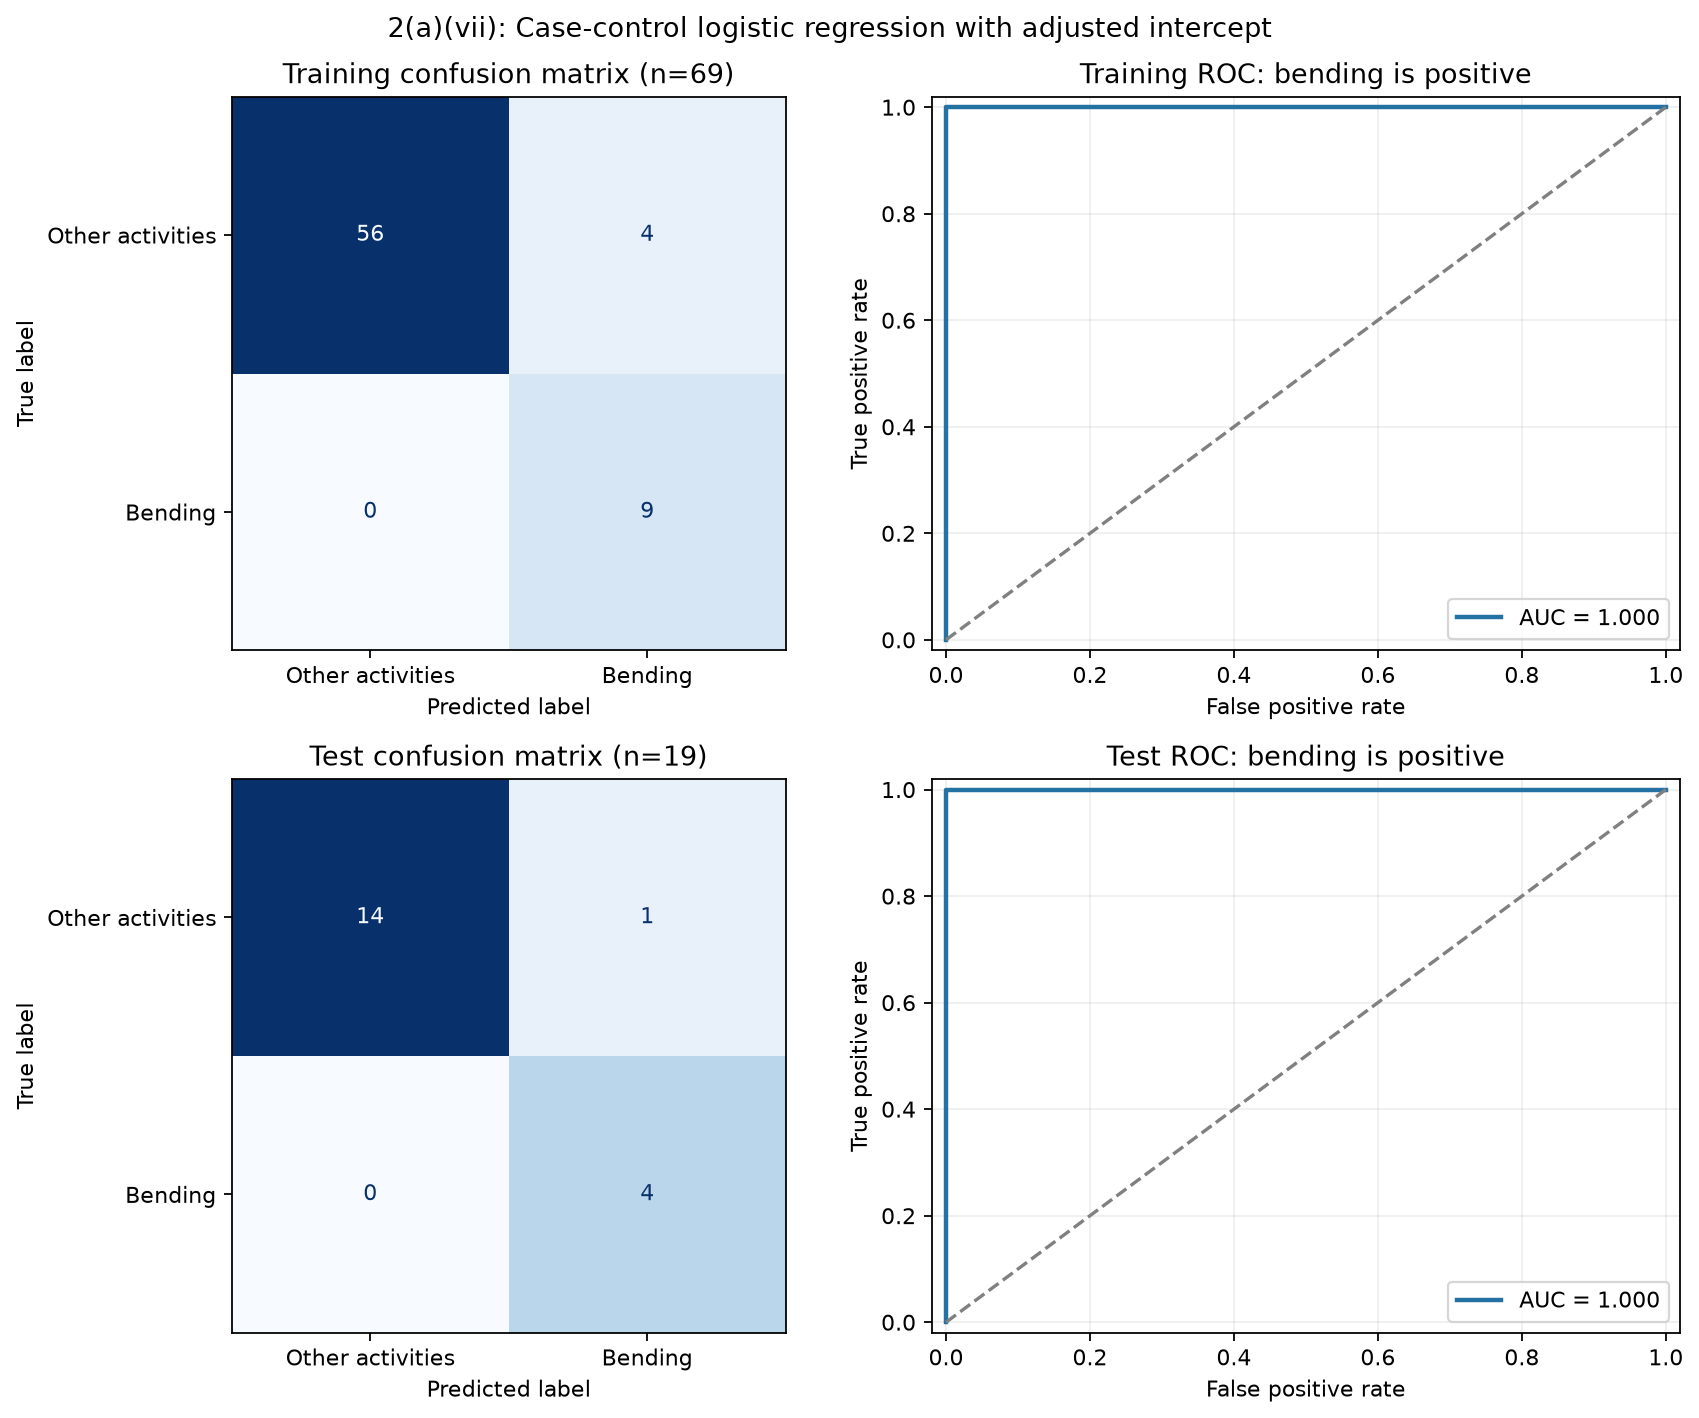

In [ ]:
case_control_results = {}
case_prediction_rows = []
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
evaluation_sets = [
    ("Training", X_train_case_features, y_binary, train_files),
    ("Test", X_test_case_features, y_test_binary, test_files),
]
for row_number, (split, X_split, y_split, split_files) in enumerate(evaluation_sets):
    unadjusted_scores = sampled_model.decision_function(X_split)
    adjusted_scores = adjusted_case_control_model.decision_function(X_split)
    np.testing.assert_allclose(adjusted_scores, unadjusted_scores + intercept_adjustment)
    probabilities = adjusted_case_control_model.predict_proba(X_split)[:, 1]
    np.testing.assert_allclose(probabilities, expit(adjusted_scores))
    predictions = (probabilities >= 0.5).astype(int)
    matrix = confusion_matrix(y_split, predictions, labels=[0, 1])
    # Decision scores avoid numerical saturation of very large probabilities.
    auc = roc_auc_score(y_split, adjusted_scores)
    assert np.isclose(auc, roc_auc_score(y_split, unadjusted_scores))
    fpr, tpr, _ = roc_curve(y_split, adjusted_scores)
    accuracy = accuracy_score(y_split, predictions)
    balanced_accuracy = balanced_accuracy_score(y_split, predictions)
    case_control_results[split.lower()] = {
        "instances": len(y_split), "confusion_matrix": matrix.tolist(),
        "accuracy": float(accuracy), "balanced_accuracy": float(balanced_accuracy), "auc": float(auc),
    }
    print(f"{split} confusion matrix (rows = actual, columns = predicted; other, bending):")
    print(matrix)
    print(f"{split} accuracy: {accuracy:.2%}; balanced accuracy: {balanced_accuracy:.2%}; AUC: {auc:.4f}")
    ConfusionMatrixDisplay(matrix, display_labels=["Other activities", "Bending"]).plot(
        ax=axes[row_number, 0], cmap="Blues", colorbar=False, values_format="d")
    axes[row_number, 0].set_title(f"{split} confusion matrix (n={len(y_split)})")
    axes[row_number, 1].plot(fpr, tpr, linewidth=2, color="#2471A3", label=f"AUC = {auc:.3f}")
    axes[row_number, 1].plot([0, 1], [0, 1], "--", color="gray")
    axes[row_number, 1].set(xlabel="False positive rate", ylabel="True positive rate",
                           title=f"{split} ROC: bending is positive", xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
    axes[row_number, 1].legend(loc="lower right")
    axes[row_number, 1].grid(alpha=0.2)
    case_prediction_rows.extend({
        "split": split.lower(), "activity": path.parent.name, "file": path.name,
        "actual_bending": int(actual), "predicted_bending": int(prediction),
        "adjusted_probability_bending": float(probability), "adjusted_score": float(score),
    } for path, actual, prediction, probability, score in
        zip(split_files, y_split, predictions, probabilities, adjusted_scores))

fig.suptitle("2(a)(vii): Case-control logistic regression with adjusted intercept")
fig.tight_layout()
fig.savefig(figure_root / "2a_vii_case_control_evaluation.png", dpi=160, bbox_inches="tight")
plt.show()
with (processed_root / "2a_vii_predictions.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(case_prediction_rows[0]))
    writer.writeheader()
    writer.writerows(case_prediction_rows)
case_control_summary = {
    "seed": 42, "l": best_l, "p": best_p,
    "sample_counts_other_bending": np.bincount(y_case_control).tolist(),
    "target_prior": target_prior, "sample_prior": sample_prior,
    "intercept_adjustment": intercept_adjustment,
    "sample_standardized_intercept": sampled_intercept, "adjusted_standardized_intercept": adjusted_intercept,
    "threshold": 0.5, "class_order": ["other activities", "bending"],
    **case_control_results,
}
(processed_root / "2a_vii_summary.json").write_text(json.dumps(case_control_summary, indent=2) + "\n")


The adjustment changed the intercept from **0.763516 to -1.133604**. I then tested the adjusted model on the full training set and the test set, using the same cutoff of 0.5.

On the training set, the model got **56 other-activity instances and all 9 bending instances correct**. It predicted bending for 4 other-activity instances, so the training accuracy was **94.20%**. On the test set, it got **14 other-activity instances and all 4 bending instances correct**, with 1 false positive. The test accuracy was **94.74%**. The AUC was **1.00** for both sets.

The AUC is perfect because the model gave every bending instance a higher score than the other activities. However, some other-activity instances still had probabilities above 0.5, which caused the false positives. Changing the intercept affects these probabilities, but it does not change their order, so the AUC stays the same.

This model did not do better than my original model, which got all the training and test instances correct. One reason could be that I only used 9 of the 60 other-activity instances to fit the new model. I kept the same random sample and adjustment instead of changing them after seeing the test results. Balancing the sample also does not fix the separation issue from part (vi), so the adjusted probabilities may still be unreliable.


### (b) Binary Classification Using L1-Penalized Logistic Regression

#### (i) Choosing the Number of Segments and Regularization Strength

I repeated part 2(a)(iii), but this time I used L1 regularization to select features. L1 regularization can shrink some coefficients to exactly zero. I kept the features with nonzero coefficients instead of using RFE or p-values.

I tried $l=1,2,\ldots,20$ and calculated the same seven statistics from all six series. This gave me $42l$ features per instance, while the number of training instances stayed at 69. I used the full training set, rather than the smaller case-control sample from part (a)(vii).

I also tried 17 values of $C$, from $10^{-4}$ to $10^4$, evenly spaced on a log scale. A smaller $C$ gives stronger regularization. This gave me 340 combinations of $l$ and $C$ to compare. I used the same stratified 5-fold splits as before and chose the pair with the highest mean balanced accuracy. I also recorded ordinary accuracy. For tied scores, I chose the smaller $l$, then the smaller $C$.

Following footnote 8, I standardized the features. I put the scaler and logistic regression model together in a pipeline, so the scaler was fitted only on the training portion of each fold. The L1 feature selection also happened inside each fold. I did not use the test set to choose $l$ or $C$.

Following footnote 9, I used the Liblinear solver with `l1_ratio=1` for an L1 penalty. Liblinear also penalizes the intercept, so I set `intercept_scaling=1000` to reduce that effect. I used seed 42 and checked that the fits stopped before the iteration limit. I referred to the documentation for [logistic regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) and [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

C_grid = np.logspace(-4, 4, 17)
l1_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("logit", LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=50000,
                                 tol=1e-6, intercept_scaling=1000, random_state=42)),
])

# Extra scoring functions record convergence and sparsity without changing fits.
def l1_converged(estimator, X, y):
    fitted = estimator.named_steps["logit"]
    return float(np.max(fitted.n_iter_) < fitted.max_iter)

def l1_nonzero_features(estimator, X, y):
    return float(np.count_nonzero(estimator.named_steps["logit"].coef_))

l1_cv_rows = []
l1_started = time.perf_counter()
with threadpool_limits(limits=1), parallel_config(backend="loky", inner_max_num_threads=1):
    for l in range(1, 21):
        search_l1 = GridSearchCV(
            estimator=l1_pipeline, param_grid={"logit__C": C_grid},
            scoring={"balanced_accuracy": "balanced_accuracy", "accuracy": "accuracy",
                     "converged": l1_converged, "nonzero_features": l1_nonzero_features},
            refit=False, cv=cv_splits, n_jobs=5, error_score="raise",
        )
        search_l1.fit(features_by_l[l], y_binary)
        results = search_l1.cv_results_
        assert np.all(results["mean_test_converged"] == 1), "Increase max_iter for nonconverged fits."
        for index, params in enumerate(results["params"]):
            row = {
                "l": l, "C": float(params["logit__C"]), "candidate_features": 42 * l,
                "mean_cv_balanced_accuracy": float(results["mean_test_balanced_accuracy"][index]),
                "std_cv_balanced_accuracy": float(results["std_test_balanced_accuracy"][index]),
                "mean_cv_accuracy": float(results["mean_test_accuracy"][index]),
                "std_cv_accuracy": float(results["std_test_accuracy"][index]),
                "mean_fold_nonzero_features": float(results["mean_test_nonzero_features"][index]),
                "all_folds_converged": bool(results["mean_test_converged"][index] == 1),
            }
            row.update({f"fold_{fold + 1}_balanced_accuracy":
                        float(results[f"split{fold}_test_balanced_accuracy"][index]) for fold in range(5)})
            row.update({f"fold_{fold + 1}_accuracy":
                        float(results[f"split{fold}_test_accuracy"][index]) for fold in range(5)})
            l1_cv_rows.append(row)
        best_score_for_l = float(np.max(results["mean_test_balanced_accuracy"]))
        first_best_index = np.flatnonzero(np.isclose(results["mean_test_balanced_accuracy"],
                                                    best_score_for_l, rtol=0, atol=1e-12))[0]
        print(f"l={l:2d}, candidate features={42*l:3d}, best C={C_grid[first_best_index]:.6g}, "
              f"CV balanced accuracy={best_score_for_l:.4f}", flush=True)

assert len(l1_cv_rows) == 20 * len(C_grid) == 340
l1_highest_score = max(row["mean_cv_balanced_accuracy"] for row in l1_cv_rows)
l1_ties = [row for row in l1_cv_rows
           if np.isclose(row["mean_cv_balanced_accuracy"], l1_highest_score, rtol=0, atol=1e-12)]
l1_best_result = min(l1_ties, key=lambda row: (row["l"], row["C"]))
l1_best_l, l1_best_C = l1_best_result["l"], l1_best_result["C"]
with (processed_root / "2b_i_cv_results.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(l1_cv_rows[0]))
    writer.writeheader()
    writer.writerows(l1_cv_rows)
print(f"Checked 340 pairs using 1,700 fold fits in {(time.perf_counter()-l1_started)/60:.1f} minutes.")
print(f"Selected pair: l={l1_best_l}, C={l1_best_C:.6g}")
print(f"Mean CV balanced accuracy: {l1_best_result['mean_cv_balanced_accuracy']:.2%}")
print(f"Mean CV ordinary accuracy: {l1_best_result['mean_cv_accuracy']:.2%}")


l= 1, candidate features= 42, best C=316.228, CV balanced accuracy=0.9417
l= 2, candidate features= 84, best C=3.16228, CV balanced accuracy=0.8833
l= 3, candidate features=126, best C=100, CV balanced accuracy=0.8833
l= 4, candidate features=168, best C=3.16228, CV balanced accuracy=0.8833
l= 5, candidate features=210, best C=31.6228, CV balanced accuracy=0.7917
l= 6, candidate features=252, best C=1000, CV balanced accuracy=0.9000
l= 7, candidate features=294, best C=3.16228, CV balanced accuracy=0.7417
l= 8, candidate features=336, best C=3.16228, CV balanced accuracy=0.7417
l= 9, candidate features=378, best C=3.16228, CV balanced accuracy=0.7000
l=10, candidate features=420, best C=1000, CV balanced accuracy=0.8417
l=11, candidate features=462, best C=3.16228, CV balanced accuracy=0.8917
l=12, candidate features=504, best C=1, CV balanced accuracy=0.9500
l=13, candidate features=546, best C=10, CV balanced accuracy=0.9000
l=14, candidate features=588, best C=3.16228, CV balanced a

In [ ]:
# Refit the chosen L1 model on all 69 training instances.
# All 42*l features enter this fit; do not apply the previous RFE mask.
final_l1_model = clone(l1_pipeline).set_params(logit__C=l1_best_C)
with warnings.catch_warnings(record=True) as l1_final_warnings, threadpool_limits(limits=1):
    warnings.simplefilter("always", ConvergenceWarning)
    final_l1_model.fit(features_by_l[l1_best_l], y_binary)
l1_logit = final_l1_model.named_steps["logit"]
assert np.max(l1_logit.n_iter_) < l1_logit.max_iter
assert not any(issubclass(w.category, ConvergenceWarning) for w in l1_final_warnings)
l1_beta = l1_logit.coef_.ravel()
l1_selected_mask = l1_beta != 0
l1_selected_names = np.array(feature_names_by_l[l1_best_l])[l1_selected_mask].tolist()
print(f"Final model keeps {int(l1_selected_mask.sum())} of {len(l1_beta)} feature coefficients nonzero.")
print(f"Final fit iterations: {int(l1_logit.n_iter_[0])}")
print(f"Intercept: {float(l1_logit.intercept_[0]):.6f}")
print("Nonzero standardized coefficients:")
for name, coefficient in zip(np.array(feature_names_by_l[l1_best_l])[l1_selected_mask], l1_beta[l1_selected_mask]):
    print(f"{name:20s} {coefficient: .6f}")

l1_coefficient_rows = [{"feature": name, "standardized_coefficient": float(coefficient),
                        "selected": bool(selected)}
                       for name, coefficient, selected in
                       zip(feature_names_by_l[l1_best_l], l1_beta, l1_selected_mask)]
with (processed_root / "2b_i_coefficients.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(l1_coefficient_rows[0]))
    writer.writeheader()
    writer.writerows(l1_coefficient_rows)
l1_summary = {
    "best_l": l1_best_l, "best_C": l1_best_C, "C_grid": C_grid.tolist(),
    "scoring": "balanced_accuracy", "candidate_pairs": len(l1_cv_rows), "fold_fits": len(l1_cv_rows) * 5,
    "mean_cv_balanced_accuracy": l1_best_result["mean_cv_balanced_accuracy"],
    "mean_cv_accuracy": l1_best_result["mean_cv_accuracy"],
    "fold_balanced_accuracy": [l1_best_result[f"fold_{fold + 1}_balanced_accuracy"] for fold in range(5)],
    "fold_accuracy": [l1_best_result[f"fold_{fold + 1}_accuracy"] for fold in range(5)],
    "candidate_features": len(l1_beta), "nonzero_features": int(l1_selected_mask.sum()),
    "selected_features": l1_selected_names, "standardized_intercept": float(l1_logit.intercept_[0]),
    "solver": l1_logit.solver, "l1_ratio": 1, "max_iter": l1_logit.max_iter,
    "intercept_scaling": l1_logit.intercept_scaling, "tol": l1_logit.tol,
    "n_iter": int(l1_logit.n_iter_[0]), "all_cv_fits_converged": True,
    "seed": 42, "test_used_in_this_part": False,
}
(processed_root / "2b_i_summary.json").write_text(json.dumps(l1_summary, indent=2) + "\n")


Final model keeps 5 of 504 feature coefficients nonzero.
Final fit iterations: 35
Intercept: -4.000859
Nonzero standardized coefficients:
median_5_seg2         0.129405
q1_5_seg2             2.488060
max_1_seg7           -0.854968
min_5_seg11           0.685391
max_6_seg11          -0.343069


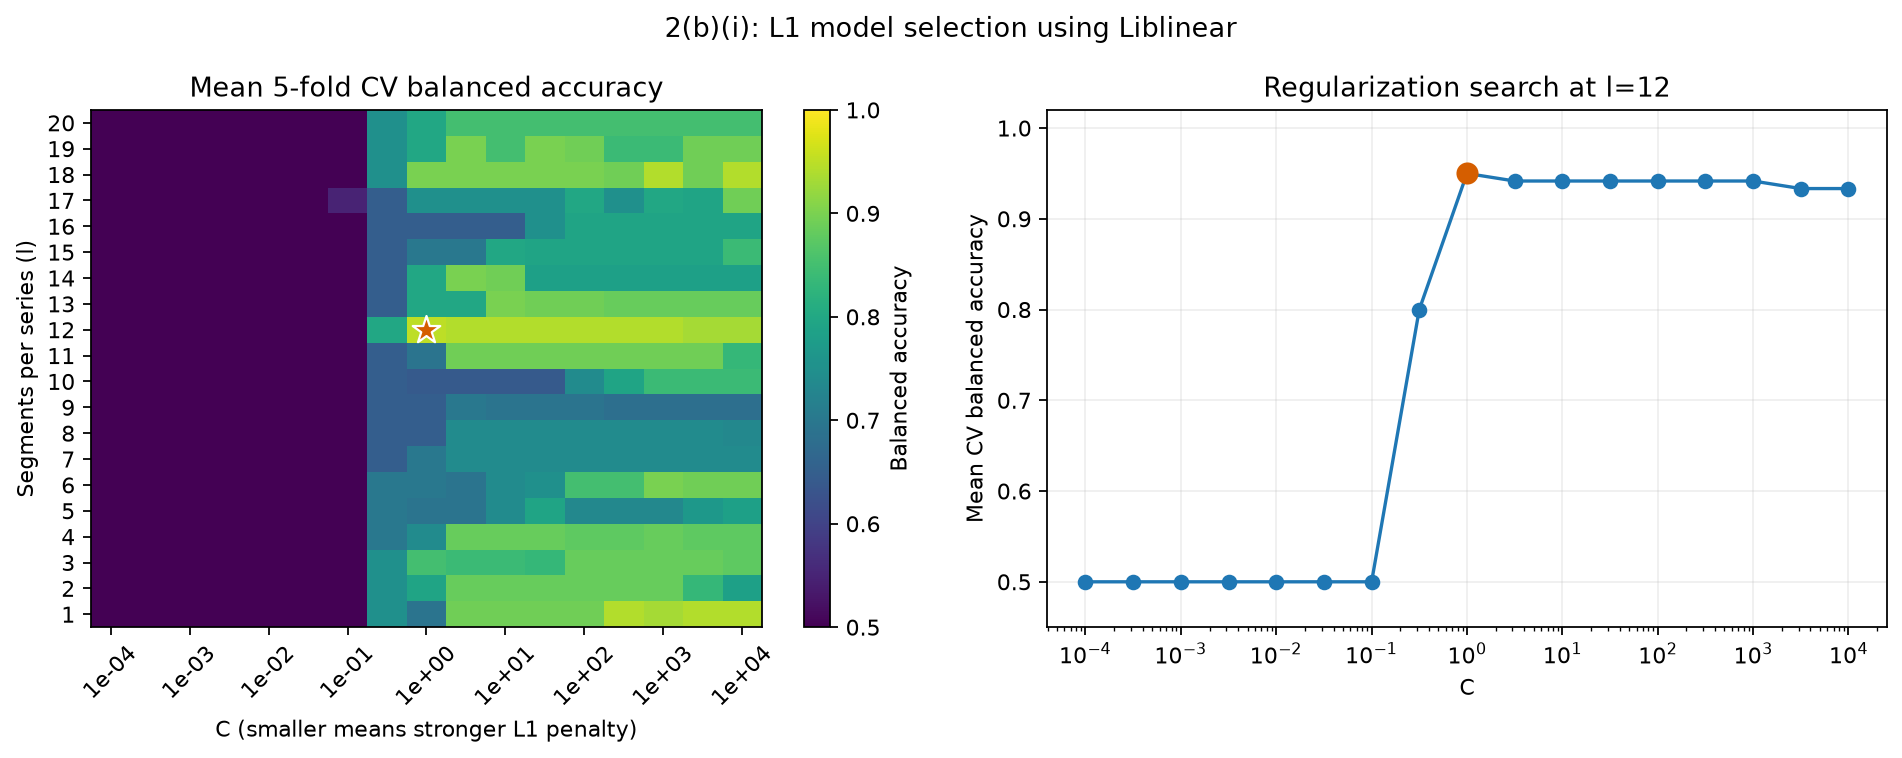

In [ ]:
score_grid = np.array([[row["mean_cv_balanced_accuracy"] for row in l1_cv_rows if row["l"] == l]
                       for l in range(1, 21)])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
image = axes[0].imshow(score_grid, origin="lower", aspect="auto", vmin=0.5, vmax=1, cmap="viridis")
axes[0].set_xticks(range(0, len(C_grid), 2), [f"{C:.0e}" for C in C_grid[::2]], rotation=45)
axes[0].set_yticks(range(20), range(1, 21))
best_C_index = int(np.flatnonzero(C_grid == l1_best_C)[0])
axes[0].scatter([best_C_index], [l1_best_l - 1], marker="*", s=170, color="#D55E00", edgecolor="white")
axes[0].set(xlabel="C (smaller means stronger L1 penalty)", ylabel="Segments per series (l)",
            title="Mean 5-fold CV balanced accuracy")
fig.colorbar(image, ax=axes[0], label="Balanced accuracy")
best_l_rows = [row for row in l1_cv_rows if row["l"] == l1_best_l]
axes[1].semilogx(C_grid, [row["mean_cv_balanced_accuracy"] for row in best_l_rows], marker="o")
axes[1].scatter([l1_best_C], [l1_highest_score], color="#D55E00", s=80, zorder=3)
axes[1].set(xlabel="C", ylabel="Mean CV balanced accuracy", title=f"Regularization search at l={l1_best_l}",
            ylim=(0.45, 1.02))
axes[1].grid(alpha=0.2)
fig.suptitle("2(b)(i): L1 model selection using Liblinear")
fig.tight_layout()
fig.savefig(figure_root / "2b_i_l1_model_selection.png", dpi=160, bbox_inches="tight")
plt.show()


The best pair I found was **$l=12$ and $C=1$**. The mean cross-validation accuracy was **98.57%**, and the mean balanced accuracy was **95.00%**. This means I split each original series into 12 segments, but still had 69 training instances.

I then fitted this model on the full training set. There were **504 candidate features**, and L1 regularization set **499 coefficients to zero**, leaving **5 nonzero coefficients**. I did not have to choose how many features to keep, since the regularization did this during fitting. The exact features kept can also depend on the solver tolerance when features are highly correlated.

All 1,700 cross-validation fits stopped before the iteration limit. The final fit stopped after 35 iterations without a convergence warning. I used the cross-validation results to choose the model, so I would still need to test it on the test set to see how well it performs on new instances.


#### (ii) Comparing L1 Regularization with Variable Selection

I compared the L1 model with my model from part (a). I used RFE in part (a), which was one of the options given in the question. I did not use p-values to select features because the classes were completely separated and the usual p-values were unreliable. So my results compare L1 with RFE.

I tested the L1 model from part (b)(i), keeping $l=12$ and $C=1$. I split each test series into 12 segments and extracted the same features as in training. I used the existing scaler and model without fitting them again on the test set.


In [ ]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix

l1_test_recordings = [np.asarray(read_time_series(path), dtype=float).T for path in test_files]
X_l1_test, l1_test_names = extract_segment_features(l1_test_recordings, l1_best_l)
l1_y_test = np.array([int(path.parent.name in {"bending1", "bending2"}) for path in test_files])
assert X_l1_test.shape == (19, 42 * l1_best_l)
assert l1_test_names == feature_names_by_l[l1_best_l]

# The pipeline applies the training-fitted scaler and L1 coefficients.
l1_test_probability = final_l1_model.predict_proba(X_l1_test)[:, list(final_l1_model.classes_).index(1)]
l1_test_prediction = (l1_test_probability >= 0.5).astype(int)
l1_test_accuracy = accuracy_score(l1_y_test, l1_test_prediction)
l1_test_balanced_accuracy = balanced_accuracy_score(l1_y_test, l1_test_prediction)
l1_test_confusion = confusion_matrix(l1_y_test, l1_test_prediction, labels=[0, 1])

comparison_rows = [
    {"method": "Unregularized + RFE (part a)",
     "mean_cv_accuracy": summary_2a_iii["mean_cv_accuracy"],
     "mean_cv_balanced_accuracy": summary_2a_iii["mean_cv_balanced_accuracy"],
     "test_accuracy": test_summary["test_accuracy"],
     "test_balanced_accuracy": test_summary["test_balanced_accuracy"],
     "selected_features": summary_2a_iii["best_p"]},
    {"method": "L1 + Liblinear (part b)",
     "mean_cv_accuracy": l1_summary["mean_cv_accuracy"],
     "mean_cv_balanced_accuracy": l1_summary["mean_cv_balanced_accuracy"],
     "test_accuracy": float(l1_test_accuracy),
     "test_balanced_accuracy": float(l1_test_balanced_accuracy),
     "selected_features": l1_summary["nonzero_features"]},
]
for row in comparison_rows:
    print(row["method"])
    print(f"  Mean CV accuracy: {row['mean_cv_accuracy']:.2%}")
    print(f"  Mean CV balanced accuracy: {row['mean_cv_balanced_accuracy']:.2%}")
    print(f"  Test accuracy: {row['test_accuracy']:.2%}")
    print(f"  Test balanced accuracy: {row['test_balanced_accuracy']:.2%}")
    print(f"  Selected features: {row['selected_features']}")
print("L1 test confusion matrix (rows = actual, columns = predicted; other, bending):")
print(l1_test_confusion)

with (processed_root / "2b_ii_model_comparison.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(comparison_rows[0]))
    writer.writeheader()
    writer.writerows(comparison_rows)
l1_test_rows = [{"activity": path.parent.name, "file": path.name,
                 "actual_bending": int(actual), "predicted_bending": int(prediction),
                 "probability_bending": float(probability)}
                for path, actual, prediction, probability in
                zip(test_files, l1_y_test, l1_test_prediction, l1_test_probability)]
with (processed_root / "2b_ii_l1_test_predictions.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(l1_test_rows[0]))
    writer.writeheader()
    writer.writerows(l1_test_rows)
comparison_summary = {"models": comparison_rows, "l1_test_confusion_matrix": l1_test_confusion.tolist(),
                      "test_threshold": 0.5,
                      "p_value_selection_status": "Not fitted; conventional p-values unreliable under complete separation"}
(processed_root / "2b_ii_summary.json").write_text(json.dumps(comparison_summary, indent=2) + "\n")


Unregularized + RFE (part a)
  Mean CV accuracy: 98.57%
  Mean CV balanced accuracy: 99.17%
  Test accuracy: 100.00%
  Test balanced accuracy: 100.00%
  Selected features: 10
L1 + Liblinear (part b)
  Mean CV accuracy: 98.57%
  Mean CV balanced accuracy: 95.00%
  Test accuracy: 94.74%
  Test balanced accuracy: 87.50%
  Selected features: 5
L1 test confusion matrix (rows = actual, columns = predicted; other, bending):
[[15  0]
 [ 1  3]]


My model from part (a) did better on the test set. It got **19 out of 19 correct (100%)**, while the L1 model got **18 out of 19 correct (94.74%)**. The L1 model missed one bending instance. Both models had the same mean CV accuracy of **98.57%**, but the RFE model had a higher mean CV balanced accuracy: **99.17% versus 95.00%**. The L1 model was smaller, using 5 features instead of 10.

I think **L1 is easier to implement than selecting features with p-values**. I can use an L1 penalty and cross-validate $C$, and the model sets some coefficients to zero. With p-values, I would need to calculate them, remove features, and fit the model again. The separation problem in this dataset also makes p-value selection difficult.

For this test set, I would choose my original RFE model based on its accuracy. However, I cannot say that p-value selection did better than L1, since I used RFE rather than p-values. There are also only 19 test instances, so this does not mean RFE will always perform better.


### (c) Multi-class Classification (The Realistic Case)

#### (i) L1-Penalized Multinomial Logistic Regression

For this part, I used all seven activity labels, keeping bending1 and bending2 separate. I split each of the six series into $l$ segments and calculated the same seven statistics as before. This gave me $42l$ features for each of the 69 training instances.

I tried $l=1,2,\ldots,20$ and 17 values of $C$ from $10^{-4}$ to $10^4$, just like in part (b). I compared the 340 pairs using mean CV balanced accuracy, which gives equal weight to the recall for each activity. I also recorded ordinary accuracy. If scores were tied, I chose the smaller $l$, then the smaller $C$.

I used **stratified 4-fold CV** because bending2 only has 4 training instances. Bending1 has 5, and each other activity has 12. With four folds, every validation fold had examples of all seven activities. I used seed 42 and kept the folds the same throughout the search.

I standardized the features inside each fold and used `solver="saga"` with `l1_ratio=1`. This fits an L1-penalized multinomial model in scikit-learn, as mentioned in footnote 10. I used SAGA here because Liblinear cannot fit the joint multinomial model. The model gives a probability for each activity, and I predict the one with the highest probability. I referred to the [scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) for the solver settings.

After choosing $l$ and $C$ from the training data, I tested the model on the 19 test instances. I used the same segmentation and features, without fitting the scaler or model again on the test set.


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

y_multi_train = np.array([path.parent.name for path in train_files])
multi_classes, multi_class_counts = np.unique(y_multi_train, return_counts=True)
assert len(multi_classes) == 7
assert multi_class_counts.tolist() == [5, 4, 12, 12, 12, 12, 12]
multi_n_splits = min(5, int(multi_class_counts.min()))
multi_cv = StratifiedKFold(n_splits=multi_n_splits, shuffle=True, random_state=42)
multi_cv_splits = list(multi_cv.split(np.zeros((69, 1)), y_multi_train))
print("Training class counts:", dict(zip(multi_classes.tolist(), multi_class_counts.tolist())))
print(f"Using stratified {multi_n_splits}-fold CV.")
for fold, (training_indices, validation_indices) in enumerate(multi_cv_splits, start=1):
    assert set(y_multi_train[validation_indices]) == set(multi_classes)
    assert set(training_indices).isdisjoint(validation_indices)
    counts = {str(activity): int(np.sum(y_multi_train[validation_indices] == activity))
              for activity in multi_classes}
    print(f"Validation fold {fold}: {counts}")

multi_C_grid = np.logspace(-4, 4, 17)
multi_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("logit", LogisticRegression(l1_ratio=1, solver="saga", max_iter=50000,
                                 tol=1e-4, random_state=42)),
])

def multi_converged(estimator, X, y):
    fitted = estimator.named_steps["logit"]
    return float(np.max(fitted.n_iter_) < fitted.max_iter)

multi_cv_rows = []
multi_search_started = time.perf_counter()
with threadpool_limits(limits=1), parallel_config(backend="loky", inner_max_num_threads=1):
    for l in range(1, 21):
        multi_search = GridSearchCV(
            multi_pipeline, {"logit__C": multi_C_grid},
            scoring={"balanced_accuracy": "balanced_accuracy", "accuracy": "accuracy",
                     "converged": multi_converged},
            refit=False, cv=multi_cv_splits, n_jobs=5, error_score="raise",
        )
        multi_search.fit(features_by_l[l], y_multi_train)
        results = multi_search.cv_results_
        assert np.all(results["mean_test_converged"] == 1), "Some fits need a higher iteration limit."
        for index, params in enumerate(results["params"]):
            row = {"l": l, "C": float(params["logit__C"]), "candidate_features": 42 * l,
                   "mean_cv_balanced_accuracy": float(results["mean_test_balanced_accuracy"][index]),
                   "std_cv_balanced_accuracy": float(results["std_test_balanced_accuracy"][index]),
                   "mean_cv_accuracy": float(results["mean_test_accuracy"][index]),
                   "all_folds_converged": bool(results["mean_test_converged"][index] == 1)}
            for fold in range(multi_n_splits):
                row[f"fold_{fold+1}_balanced_accuracy"] = float(results[f"split{fold}_test_balanced_accuracy"][index])
                row[f"fold_{fold+1}_accuracy"] = float(results[f"split{fold}_test_accuracy"][index])
            multi_cv_rows.append(row)
        # Save completed segment counts as the search progresses.
        with (processed_root / "2c_i_cv_results.csv").open("w", newline="") as file:
            writer = csv.DictWriter(file, fieldnames=list(multi_cv_rows[0]))
            writer.writeheader()
            writer.writerows(multi_cv_rows)
        highest_for_l = float(np.max(results["mean_test_balanced_accuracy"]))
        first_best = np.flatnonzero(np.isclose(results["mean_test_balanced_accuracy"], highest_for_l,
                                               rtol=0, atol=1e-12))[0]
        print(f"l={l:2d}, best C={multi_C_grid[first_best]:.6g}, "
              f"CV balanced accuracy={highest_for_l:.4f}", flush=True)

assert len(multi_cv_rows) == 340
multi_highest_score = max(row["mean_cv_balanced_accuracy"] for row in multi_cv_rows)
multi_ties = [row for row in multi_cv_rows
              if np.isclose(row["mean_cv_balanced_accuracy"], multi_highest_score, rtol=0, atol=1e-12)]
multi_best_result = min(multi_ties, key=lambda row: (row["l"], row["C"]))
multi_best_l, multi_best_C = multi_best_result["l"], multi_best_result["C"]
print(f"Compared 340 pairs with {340*multi_n_splits:,} fold fits in {(time.perf_counter()-multi_search_started)/60:.1f} minutes.")
print(f"Best pair: l={multi_best_l}, C={multi_best_C:.6g}")
print(f"Mean CV balanced accuracy: {multi_best_result['mean_cv_balanced_accuracy']:.2%}")
print(f"Mean CV accuracy: {multi_best_result['mean_cv_accuracy']:.2%}")


Training class counts: {'bending1': 5, 'bending2': 4, 'cycling': 12, 'lying': 12, 'sitting': 12, 'standing': 12, 'walking': 12}
Using stratified 4-fold CV.
Validation fold 1: {'bending1': 2, 'bending2': 1, 'cycling': 3, 'lying': 3, 'sitting': 3, 'standing': 3, 'walking': 3}
Validation fold 2: {'bending1': 1, 'bending2': 1, 'cycling': 3, 'lying': 3, 'sitting': 3, 'standing': 3, 'walking': 3}
Validation fold 3: {'bending1': 1, 'bending2': 1, 'cycling': 3, 'lying': 3, 'sitting': 3, 'standing': 3, 'walking': 3}
Validation fold 4: {'bending1': 1, 'bending2': 1, 'cycling': 3, 'lying': 3, 'sitting': 3, 'standing': 3, 'walking': 3}
l= 1, best C=31.6228, CV balanced accuracy=0.8452
l= 2, best C=316.228, CV balanced accuracy=0.8690
l= 3, best C=1000, CV balanced accuracy=0.8452
l= 4, best C=316.228, CV balanced accuracy=0.8333
l= 5, best C=1000, CV balanced accuracy=0.8571
l= 6, best C=3162.28, CV balanced accuracy=0.8571
l= 7, best C=1000, CV balanced accuracy=0.8095
l= 8, best C=316.228, CV ba

Test errors: 3/19 = 15.79%
Test accuracy: 84.21%
Test balanced accuracy: 83.33%
Class order: ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
Test confusion matrix (rows = actual, columns = predicted):
[[2 0 0 0 0 0 0]
 [0 1 0 0 1 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [1 0 0 0 1 1 0]
 [0 0 0 0 0 3 0]
 [0 0 0 0 0 0 3]]
              precision    recall  f1-score   support

    bending1       0.67      1.00      0.80         2
    bending2       1.00      0.50      0.67         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      1.00      1.00         3
     sitting       0.50      0.33      0.40         3
    standing       0.75      1.00      0.86         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.84        19
   macro avg       0.85      0.83      0.82        19
weighted avg       0.85      0.84      0.83        19

Misclassified test instances:
bending2/dataset2.csv

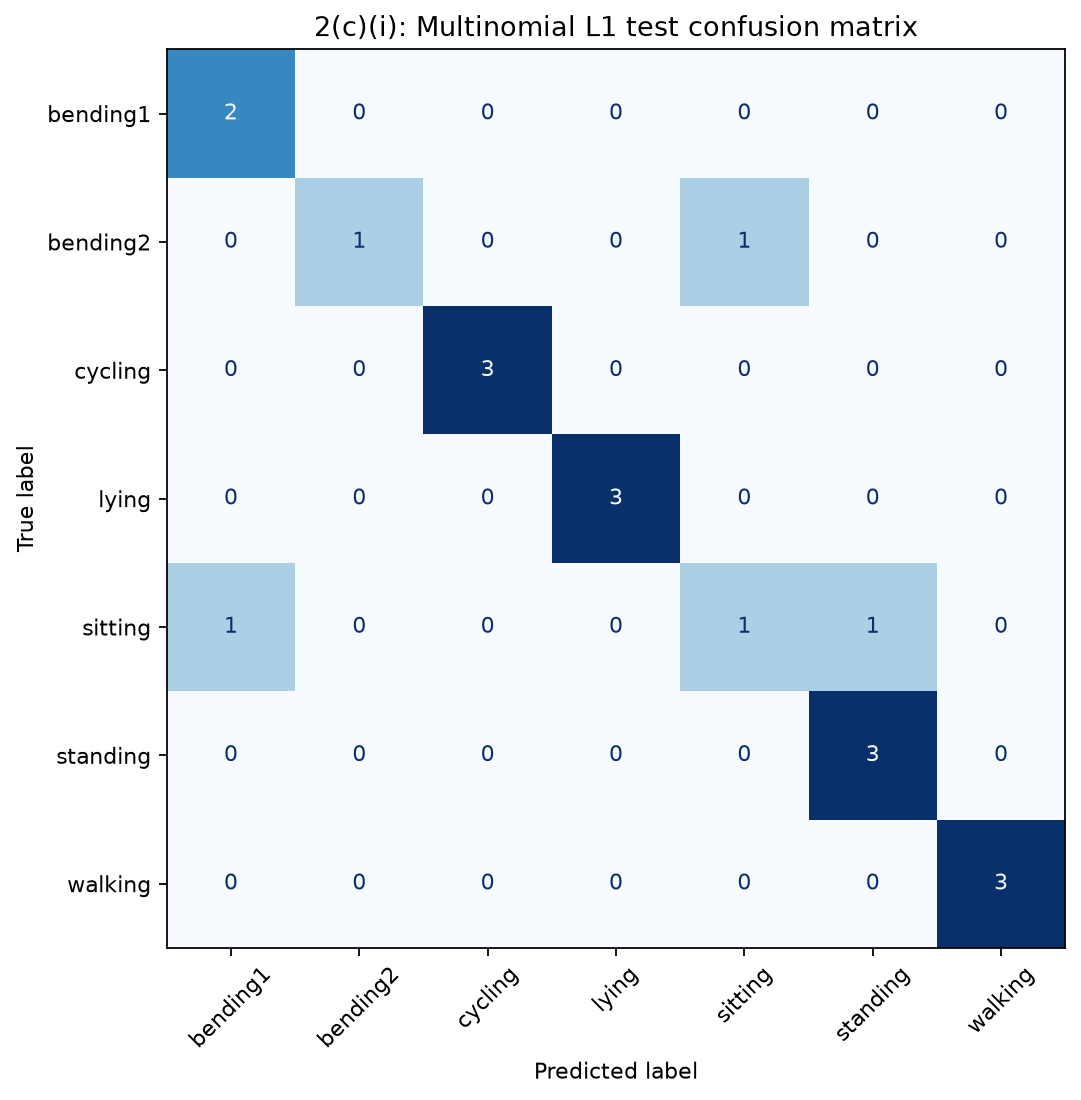

In [ ]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

final_multi_model = clone(multi_pipeline).set_params(logit__C=multi_best_C)
with warnings.catch_warnings(record=True) as multi_final_warnings, threadpool_limits(limits=1):
    warnings.simplefilter("always", ConvergenceWarning)
    final_multi_model.fit(features_by_l[multi_best_l], y_multi_train)
multi_logit = final_multi_model.named_steps["logit"]
assert np.max(multi_logit.n_iter_) < multi_logit.max_iter
assert not any(issubclass(w.category, ConvergenceWarning) for w in multi_final_warnings)
assert multi_logit.coef_.shape == (7, 42 * multi_best_l)

multi_test_recordings = [np.asarray(read_time_series(path), dtype=float).T for path in test_files]
X_multi_test, multi_test_feature_names = extract_segment_features(multi_test_recordings, multi_best_l)
y_multi_test = np.array([path.parent.name for path in test_files])
assert multi_test_feature_names == feature_names_by_l[multi_best_l]
assert X_multi_test.shape == (19, 42 * multi_best_l)
assert set(train_files).isdisjoint(test_files)
multi_probabilities = final_multi_model.predict_proba(X_multi_test)
multi_predictions = final_multi_model.classes_[np.argmax(multi_probabilities, axis=1)]
np.testing.assert_allclose(multi_probabilities.sum(axis=1), 1, atol=1e-12)
np.testing.assert_array_equal(multi_predictions, final_multi_model.predict(X_multi_test))
np.testing.assert_array_equal(final_multi_model.classes_, multi_classes)

multi_test_accuracy = accuracy_score(y_multi_test, multi_predictions)
multi_test_error = 1 - multi_test_accuracy
multi_test_balanced_accuracy = balanced_accuracy_score(y_multi_test, multi_predictions)
multi_test_confusion = confusion_matrix(y_multi_test, multi_predictions, labels=multi_classes)
assert multi_test_confusion.shape == (7, 7) and multi_test_confusion.sum() == 19
multi_errors = int(np.sum(multi_predictions != y_multi_test))
print(f"Test errors: {multi_errors}/19 = {multi_test_error:.2%}")
print(f"Test accuracy: {multi_test_accuracy:.2%}")
print(f"Test balanced accuracy: {multi_test_balanced_accuracy:.2%}")
print("Class order:", multi_classes.tolist())
print("Test confusion matrix (rows = actual, columns = predicted):")
print(multi_test_confusion)
print(classification_report(y_multi_test, multi_predictions, labels=multi_classes, zero_division=0))
print("Misclassified test instances:")
for path, actual, prediction in zip(test_files, y_multi_test, multi_predictions):
    if actual != prediction:
        print(f"{path.parent.name}/{path.name}: actual={actual}, predicted={prediction}")

fig, ax = plt.subplots(figsize=(8.5, 7))
ConfusionMatrixDisplay(multi_test_confusion, display_labels=multi_classes).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d", xticks_rotation=45)
ax.set_title("2(c)(i): Multinomial L1 test confusion matrix")
fig.tight_layout()
fig.savefig(figure_root / "2c_i_test_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

multi_prediction_rows = []
for path, actual, prediction, probabilities in zip(test_files, y_multi_test, multi_predictions, multi_probabilities):
    row = {"activity": path.parent.name, "file": path.name, "actual": str(actual), "predicted": str(prediction)}
    row.update({f"probability_{activity}": float(probability)
                for activity, probability in zip(multi_classes, probabilities)})
    multi_prediction_rows.append(row)
with (processed_root / "2c_i_test_predictions.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(multi_prediction_rows[0]))
    writer.writeheader()
    writer.writerows(multi_prediction_rows)

multi_coefficient_rows = []
for activity, intercept, coefficients in zip(multi_classes, multi_logit.intercept_, multi_logit.coef_):
    multi_coefficient_rows.append({"class": str(activity), "parameter": "Intercept", "standardized_coefficient": float(intercept)})
    multi_coefficient_rows.extend({"class": str(activity), "parameter": name, "standardized_coefficient": float(coefficient)}
                                  for name, coefficient in zip(feature_names_by_l[multi_best_l], coefficients))
with (processed_root / "2c_i_coefficients.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(multi_coefficient_rows[0]))
    writer.writeheader()
    writer.writerows(multi_coefficient_rows)


For the multiclass confusion matrix, I used one row and one column for each activity. The rows show the actual labels, and the columns show the predicted labels. The diagonal entries are correct predictions, while the other entries show the mistakes. I used the [scikit-learn definition](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).

To draw the ROC curves, I treated one activity as positive and all the others as negative, then repeated this for each activity. I used the probabilities from the same multinomial model, rather than fitting separate binary models. All seven activities appear in the test set, so I could draw a curve for each one.

I also calculated macro AUC by averaging the seven class AUCs. For micro AUC, I pooled the results across the classes. Footnote 11 gives R's pROC package as an example, but I used Python and followed the [scikit-learn multiclass ROC example](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html).


bending1  : OvR AUC = 1.0000
bending2  : OvR AUC = 0.7941
cycling   : OvR AUC = 1.0000
lying     : OvR AUC = 1.0000
sitting   : OvR AUC = 0.8958
standing  : OvR AUC = 1.0000
walking   : OvR AUC = 1.0000
Macro OvR AUC: 0.9557
Micro OvR AUC: 0.9718


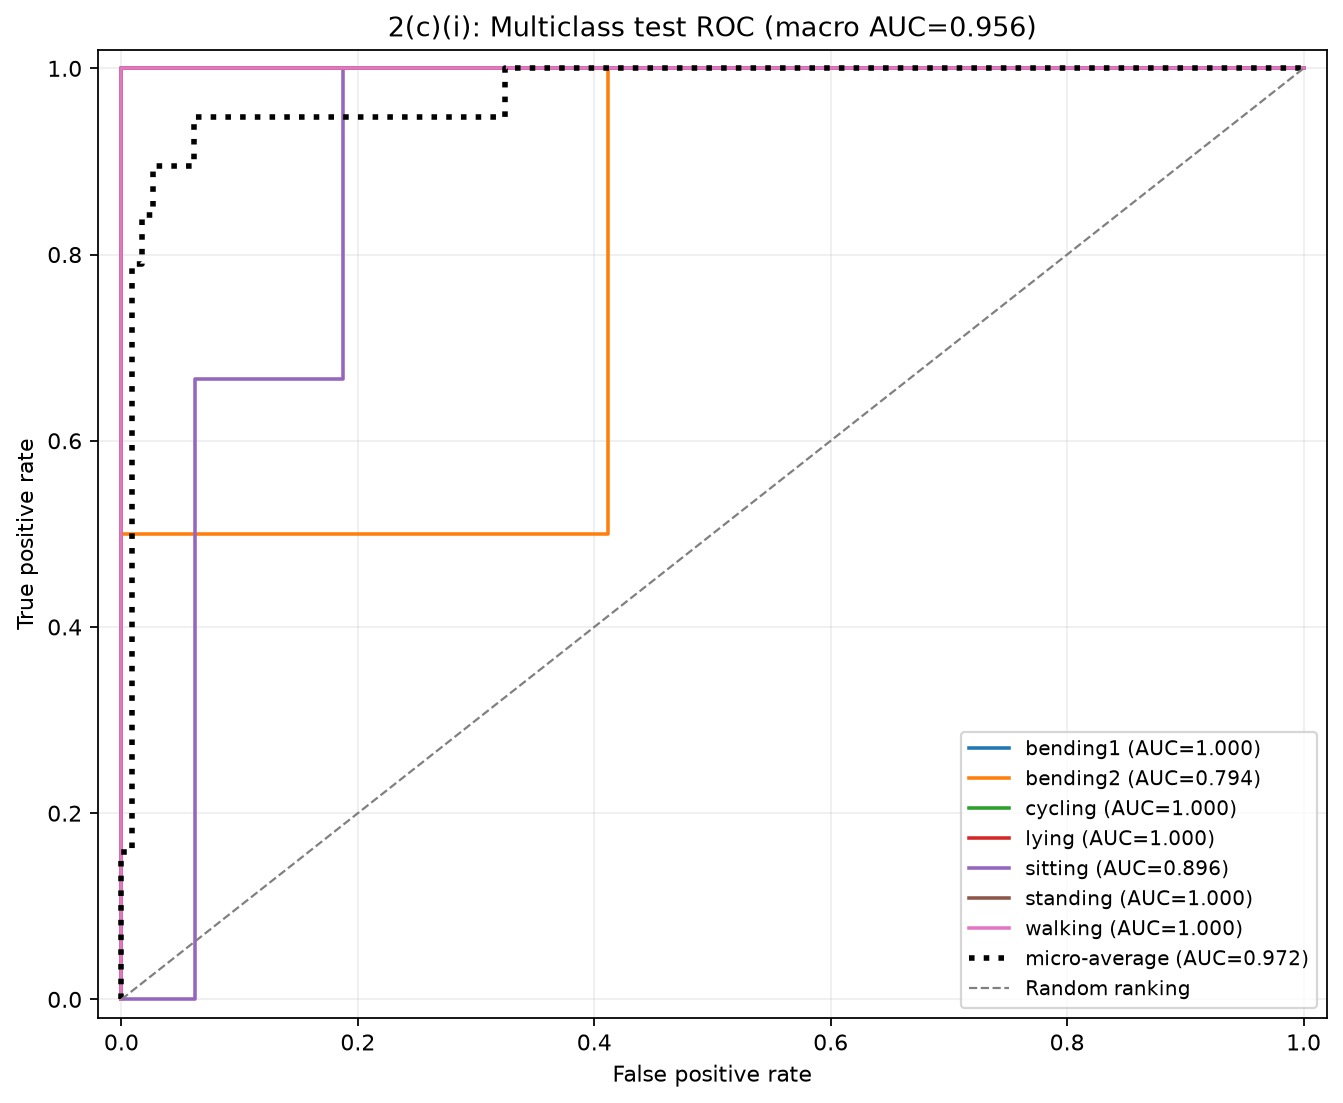

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, roc_auc_score, auc

multi_test_indicators = label_binarize(y_multi_test, classes=multi_classes)
assert multi_test_indicators.shape == multi_probabilities.shape == (19, 7)
multi_auc_rows = []
fig, ax = plt.subplots(figsize=(8.5, 7))
for column, activity in enumerate(multi_classes):
    truth = multi_test_indicators[:, column]
    assert set(truth) == {0, 1}
    fpr, tpr, _ = roc_curve(truth, multi_probabilities[:, column])
    class_auc = roc_auc_score(truth, multi_probabilities[:, column])
    multi_auc_rows.append({"activity": str(activity), "test_support": int(truth.sum()), "ovr_auc": float(class_auc)})
    ax.plot(fpr, tpr, linewidth=1.6, label=f"{activity} (AUC={class_auc:.3f})")
    print(f"{activity:10s}: OvR AUC = {class_auc:.4f}")

multi_macro_auc = roc_auc_score(y_multi_test, multi_probabilities, multi_class="ovr", average="macro", labels=multi_classes)
micro_fpr, micro_tpr, _ = roc_curve(multi_test_indicators.ravel(), multi_probabilities.ravel())
multi_micro_auc = auc(micro_fpr, micro_tpr)
np.testing.assert_allclose(multi_macro_auc, np.mean([row["ovr_auc"] for row in multi_auc_rows]))
np.testing.assert_allclose(multi_micro_auc, roc_auc_score(multi_test_indicators, multi_probabilities, average="micro"))
ax.plot(micro_fpr, micro_tpr, color="black", linestyle=":", linewidth=2.5,
        label=f"micro-average (AUC={multi_micro_auc:.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1, label="Random ranking")
ax.set(xlabel="False positive rate", ylabel="True positive rate", xlim=(-0.02, 1.02), ylim=(-0.02, 1.02),
       title=f"2(c)(i): Multiclass test ROC (macro AUC={multi_macro_auc:.3f})")
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(figure_root / "2c_i_test_roc.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"Macro OvR AUC: {multi_macro_auc:.4f}")
print(f"Micro OvR AUC: {multi_micro_auc:.4f}")
with (processed_root / "2c_i_class_auc.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(multi_auc_rows[0]))
    writer.writeheader()
    writer.writerows(multi_auc_rows)
multi_summary = {
    "best_l": multi_best_l, "best_C": multi_best_C, "C_grid": multi_C_grid.tolist(),
    "cv_folds": multi_n_splits, "cv_scoring": "balanced_accuracy", "candidate_pairs": len(multi_cv_rows),
    "mean_cv_accuracy": multi_best_result["mean_cv_accuracy"],
    "mean_cv_balanced_accuracy": multi_best_result["mean_cv_balanced_accuracy"],
    "fold_accuracy": [multi_best_result[f"fold_{fold+1}_accuracy"] for fold in range(multi_n_splits)],
    "fold_balanced_accuracy": [multi_best_result[f"fold_{fold+1}_balanced_accuracy"] for fold in range(multi_n_splits)],
    "classes": multi_classes.tolist(), "training_class_counts": multi_class_counts.tolist(),
    "test_accuracy": float(multi_test_accuracy), "test_error": float(multi_test_error), "test_errors": multi_errors,
    "test_balanced_accuracy": float(multi_test_balanced_accuracy), "test_instances": len(y_multi_test),
    "test_confusion_matrix": multi_test_confusion.tolist(),
    "class_auc": multi_auc_rows, "macro_ovr_auc": float(multi_macro_auc), "micro_ovr_auc": float(multi_micro_auc),
    "features_with_any_nonzero_coefficient": int(np.any(multi_logit.coef_ != 0, axis=0).sum()),
    "nonzero_class_coefficients": int(np.count_nonzero(multi_logit.coef_)), "candidate_features": 42 * multi_best_l,
    "solver": multi_logit.solver, "l1_ratio": 1, "max_iter": multi_logit.max_iter, "tol": multi_logit.tol,
    "n_iter": int(multi_logit.n_iter_[0]), "seed": 42, "all_cv_fits_converged": True,
}
(processed_root / "2c_i_summary.json").write_text(json.dumps(multi_summary, indent=2) + "\n")


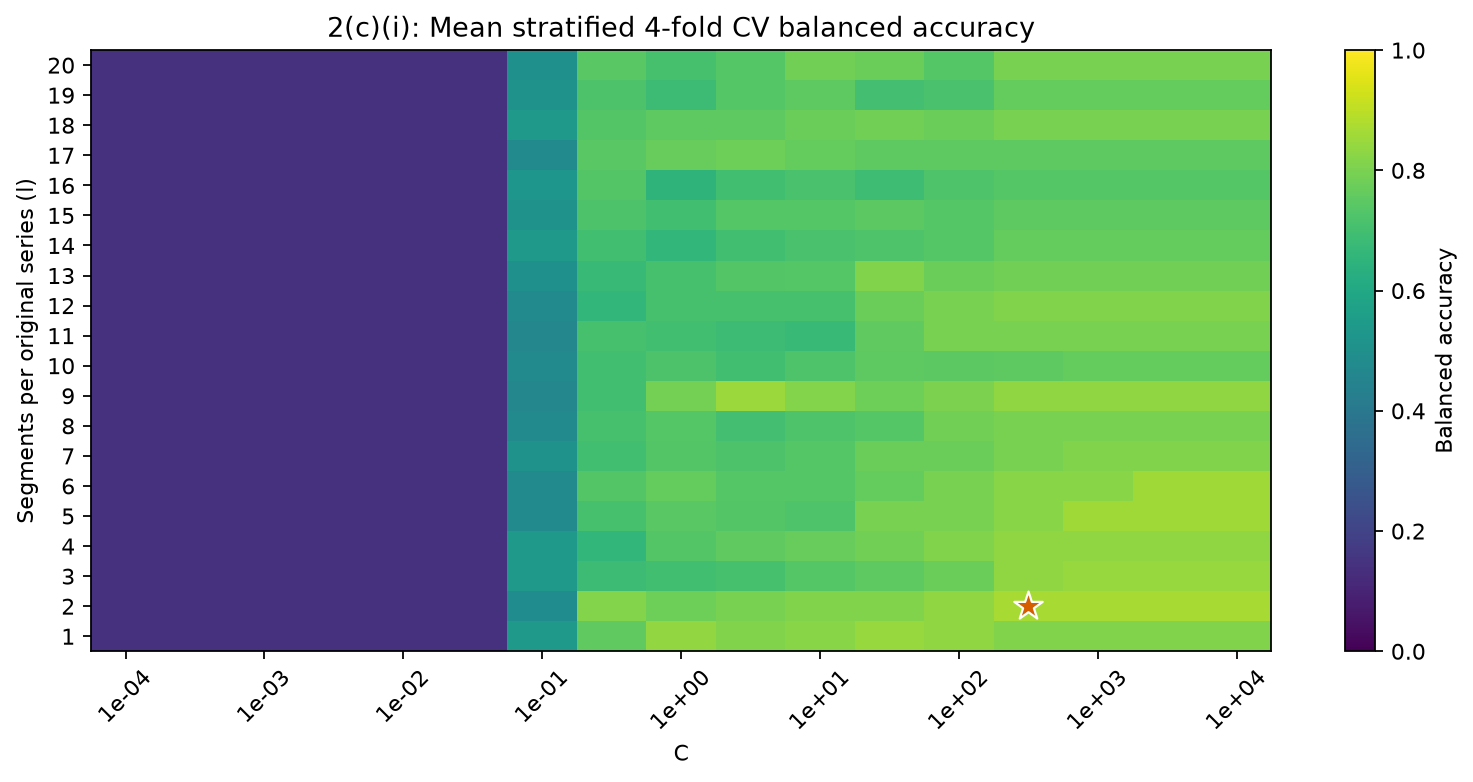

In [ ]:
multi_score_grid = np.array([[row["mean_cv_balanced_accuracy"] for row in multi_cv_rows if row["l"] == l]
                             for l in range(1, 21)])
fig, ax = plt.subplots(figsize=(10, 5))
image = ax.imshow(multi_score_grid, origin="lower", aspect="auto", vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(0, len(multi_C_grid), 2), [f"{C:.0e}" for C in multi_C_grid[::2]], rotation=45)
ax.set_yticks(range(20), range(1, 21))
chosen_C_column = int(np.flatnonzero(multi_C_grid == multi_best_C)[0])
ax.scatter([chosen_C_column], [multi_best_l-1], marker="*", s=180, color="#D55E00", edgecolor="white")
ax.set(xlabel="C", ylabel="Segments per original series (l)",
       title="2(c)(i): Mean stratified 4-fold CV balanced accuracy")
fig.colorbar(image, ax=ax, label="Balanced accuracy")
fig.tight_layout()
fig.savefig(figure_root / "2c_i_model_selection.png", dpi=160, bbox_inches="tight")
plt.show()


The best pair I found was **$l=2$ and $C\approx316.23$**. The mean CV accuracy was **92.73%**, and the mean CV balanced accuracy was **86.90%**. I then fitted this model on all 69 training instances, using 84 candidate features for each instance.

The model got **16 out of 19 test instances correct**, so the test accuracy was **84.21%**. It made 3 mistakes, giving a test error of

$$\text{Test error}=\frac{3}{19}\times100\%\approx15.79\%.$$

From the confusion matrix, one bending2 instance was predicted as sitting. Two sitting instances were also wrong: one was predicted as standing and the other as bending1. The remaining test instances were classified correctly.

The AUC was **1.0000** for bending1, cycling, lying, standing, and walking. It was **0.7941** for bending2 and **0.8958** for sitting. The **macro AUC was 0.9557**, and the **micro AUC was 0.9718**. These high AUCs do not mean every prediction is correct. The ROC curves look at how each activity is ranked against the others, while the final prediction uses whichever activity has the highest probability.

My test accuracy was lower than the CV accuracy. There are only 2 test instances for each bending activity and 3 for each other activity, so a few mistakes have a large effect on the results. I kept the model chosen from training without changing it after seeing the test results.


#### (ii) Gaussian and Multinomial Naive Bayes

I repeated part (c)(i) using Gaussian NB and Multinomial NB. I used the same seven activities, 69 training instances, and 19 test instances. For each model, I tried $l=1,2,\ldots,20$ and calculated the same seven statistics from each segment.

I used stratified 4-fold CV again because bending2 only has 4 training instances. I chose the settings with the highest mean balanced accuracy and also recorded ordinary accuracy. For Gaussian NB, I tried 15 values of `var_smoothing` from $10^{-12}$ to $10^2$. For Multinomial NB, I tried 13 values of `alpha` from $10^{-4}$ to $10^2$. This gave me 560 parameter pairs in total. For tied scores, I chose the smaller $l$, then the larger smoothing value.

I standardized the features for Gaussian NB. For Multinomial NB, I used `MaxAbsScaler` because it keeps the feature values nonnegative. Standardizing by subtracting the mean would give some negative values, which Multinomial NB cannot use. I fitted the scaler only on the training portion of each fold.

Gaussian NB models each feature with a Gaussian distribution within each activity. Multinomial NB usually works with counts, so using my continuous sensor statistics as fractional inputs is an approximation. Both models estimated the activity priors from the training class counts. I used the [GaussianNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html) and [MultinomialNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html) documentation as references.


In [ ]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MaxAbsScaler
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

nb_y_train = np.array([path.parent.name for path in train_files])
nb_classes, nb_counts = np.unique(nb_y_train, return_counts=True)
nb_n_splits = min(5, int(nb_counts.min()))
nb_cv_splits = list(StratifiedKFold(n_splits=nb_n_splits, shuffle=True, random_state=42).split(
    np.zeros((69, 1)), nb_y_train))
assert nb_n_splits == 4
assert all(set(nb_y_train[validation]) == set(nb_classes) for _, validation in nb_cv_splits)
assert all(np.all(X >= 0) for X in features_by_l.values())

nb_specs = {
    "Gaussian NB": {
        "pipeline": Pipeline([("scale", StandardScaler()), ("nb", GaussianNB())]),
        "parameter": "var_smoothing", "grid": np.logspace(-12, 2, 15),
    },
    "Multinomial NB": {
        "pipeline": Pipeline([("scale", MaxAbsScaler()), ("nb", MultinomialNB(fit_prior=True))]),
        "parameter": "alpha", "grid": np.logspace(-4, 2, 13),
    },
}
nb_cv_rows = []
nb_best = {}
with threadpool_limits(limits=1):
    for method, spec in nb_specs.items():
        for l in range(1, 21):
            search = GridSearchCV(
                spec["pipeline"], {f"nb__{spec['parameter']}": spec["grid"]},
                cv=nb_cv_splits, scoring={"balanced_accuracy": "balanced_accuracy", "accuracy": "accuracy"},
                refit=False, n_jobs=1, error_score="raise",
            )
            search.fit(features_by_l[l], nb_y_train)
            results = search.cv_results_
            for index, params in enumerate(results["params"]):
                row = {"model": method, "l": l, "parameter": spec["parameter"],
                       "parameter_value": float(params[f"nb__{spec['parameter']}"]),
                       "mean_cv_balanced_accuracy": float(results["mean_test_balanced_accuracy"][index]),
                       "mean_cv_accuracy": float(results["mean_test_accuracy"][index])}
                for fold in range(nb_n_splits):
                    row[f"fold_{fold+1}_balanced_accuracy"] = float(results[f"split{fold}_test_balanced_accuracy"][index])
                    row[f"fold_{fold+1}_accuracy"] = float(results[f"split{fold}_test_accuracy"][index])
                nb_cv_rows.append(row)
        model_rows = [row for row in nb_cv_rows if row["model"] == method]
        highest = max(row["mean_cv_balanced_accuracy"] for row in model_rows)
        ties = [row for row in model_rows if np.isclose(row["mean_cv_balanced_accuracy"], highest, rtol=0, atol=1e-12)]
        nb_best[method] = min(ties, key=lambda row: (row["l"], -row["parameter_value"]))
        chosen = nb_best[method]
        print(f"{method}: l={chosen['l']}, {chosen['parameter']}={chosen['parameter_value']:.6g}, "
              f"CV balanced accuracy={chosen['mean_cv_balanced_accuracy']:.2%}, "
              f"CV accuracy={chosen['mean_cv_accuracy']:.2%}", flush=True)
assert len(nb_cv_rows) == 560
with (processed_root / "2c_ii_cv_results.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(nb_cv_rows[0]))
    writer.writeheader()
    writer.writerows(nb_cv_rows)


Gaussian NB: l=1, var_smoothing=0.1, CV balanced accuracy=90.48%, CV accuracy=91.18%
Multinomial NB: l=10, alpha=0.1, CV balanced accuracy=79.17%, CV accuracy=84.07%


After choosing the settings, I fitted each model on all the training data. I split the test series using that model's chosen value of $l$ and extracted the same features. I used the existing scaler without fitting it again on the test set.

I made the confusion matrices and one-vs-rest ROC curves in the same way as part (c)(i). For ROC, I used `predict_log_proba` because some Naive Bayes probabilities can become too small to store accurately. The log scores keep the same intended ranking. I still predicted the activity with the highest posterior probability.


Gaussian NB: 1/19 test errors (5.26%), accuracy=94.74%, balanced accuracy=95.24%, macro AUC=1.0000, micro AUC=0.9995
Confusion matrix (rows = actual, columns = predicted):
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 3 0 0]
 [0 0 0 0 1 2 0]
 [0 0 0 0 0 0 3]]
Class prior probabilities: {'bending1': 0.07246376811594203, 'bending2': 0.057971014492753624, 'cycling': 0.17391304347826086, 'lying': 0.17391304347826086, 'sitting': 0.17391304347826086, 'standing': 0.17391304347826086, 'walking': 0.17391304347826086}
Multinomial NB: 5/19 test errors (26.32%), accuracy=73.68%, balanced accuracy=71.43%, macro AUC=0.9708, micro AUC=0.9741
Confusion matrix (rows = actual, columns = predicted):
[[2 0 0 0 0 0 0]
 [1 0 0 0 0 1 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 1 1 1 0]
 [0 0 0 0 0 0 3]]
Class prior probabilities: {'bending1': 0.07246376811594202, 'bending2': 0.05797101449275362, 'cycling': 0.17391304347826084, 'lying': 0.17391304347826084, 's

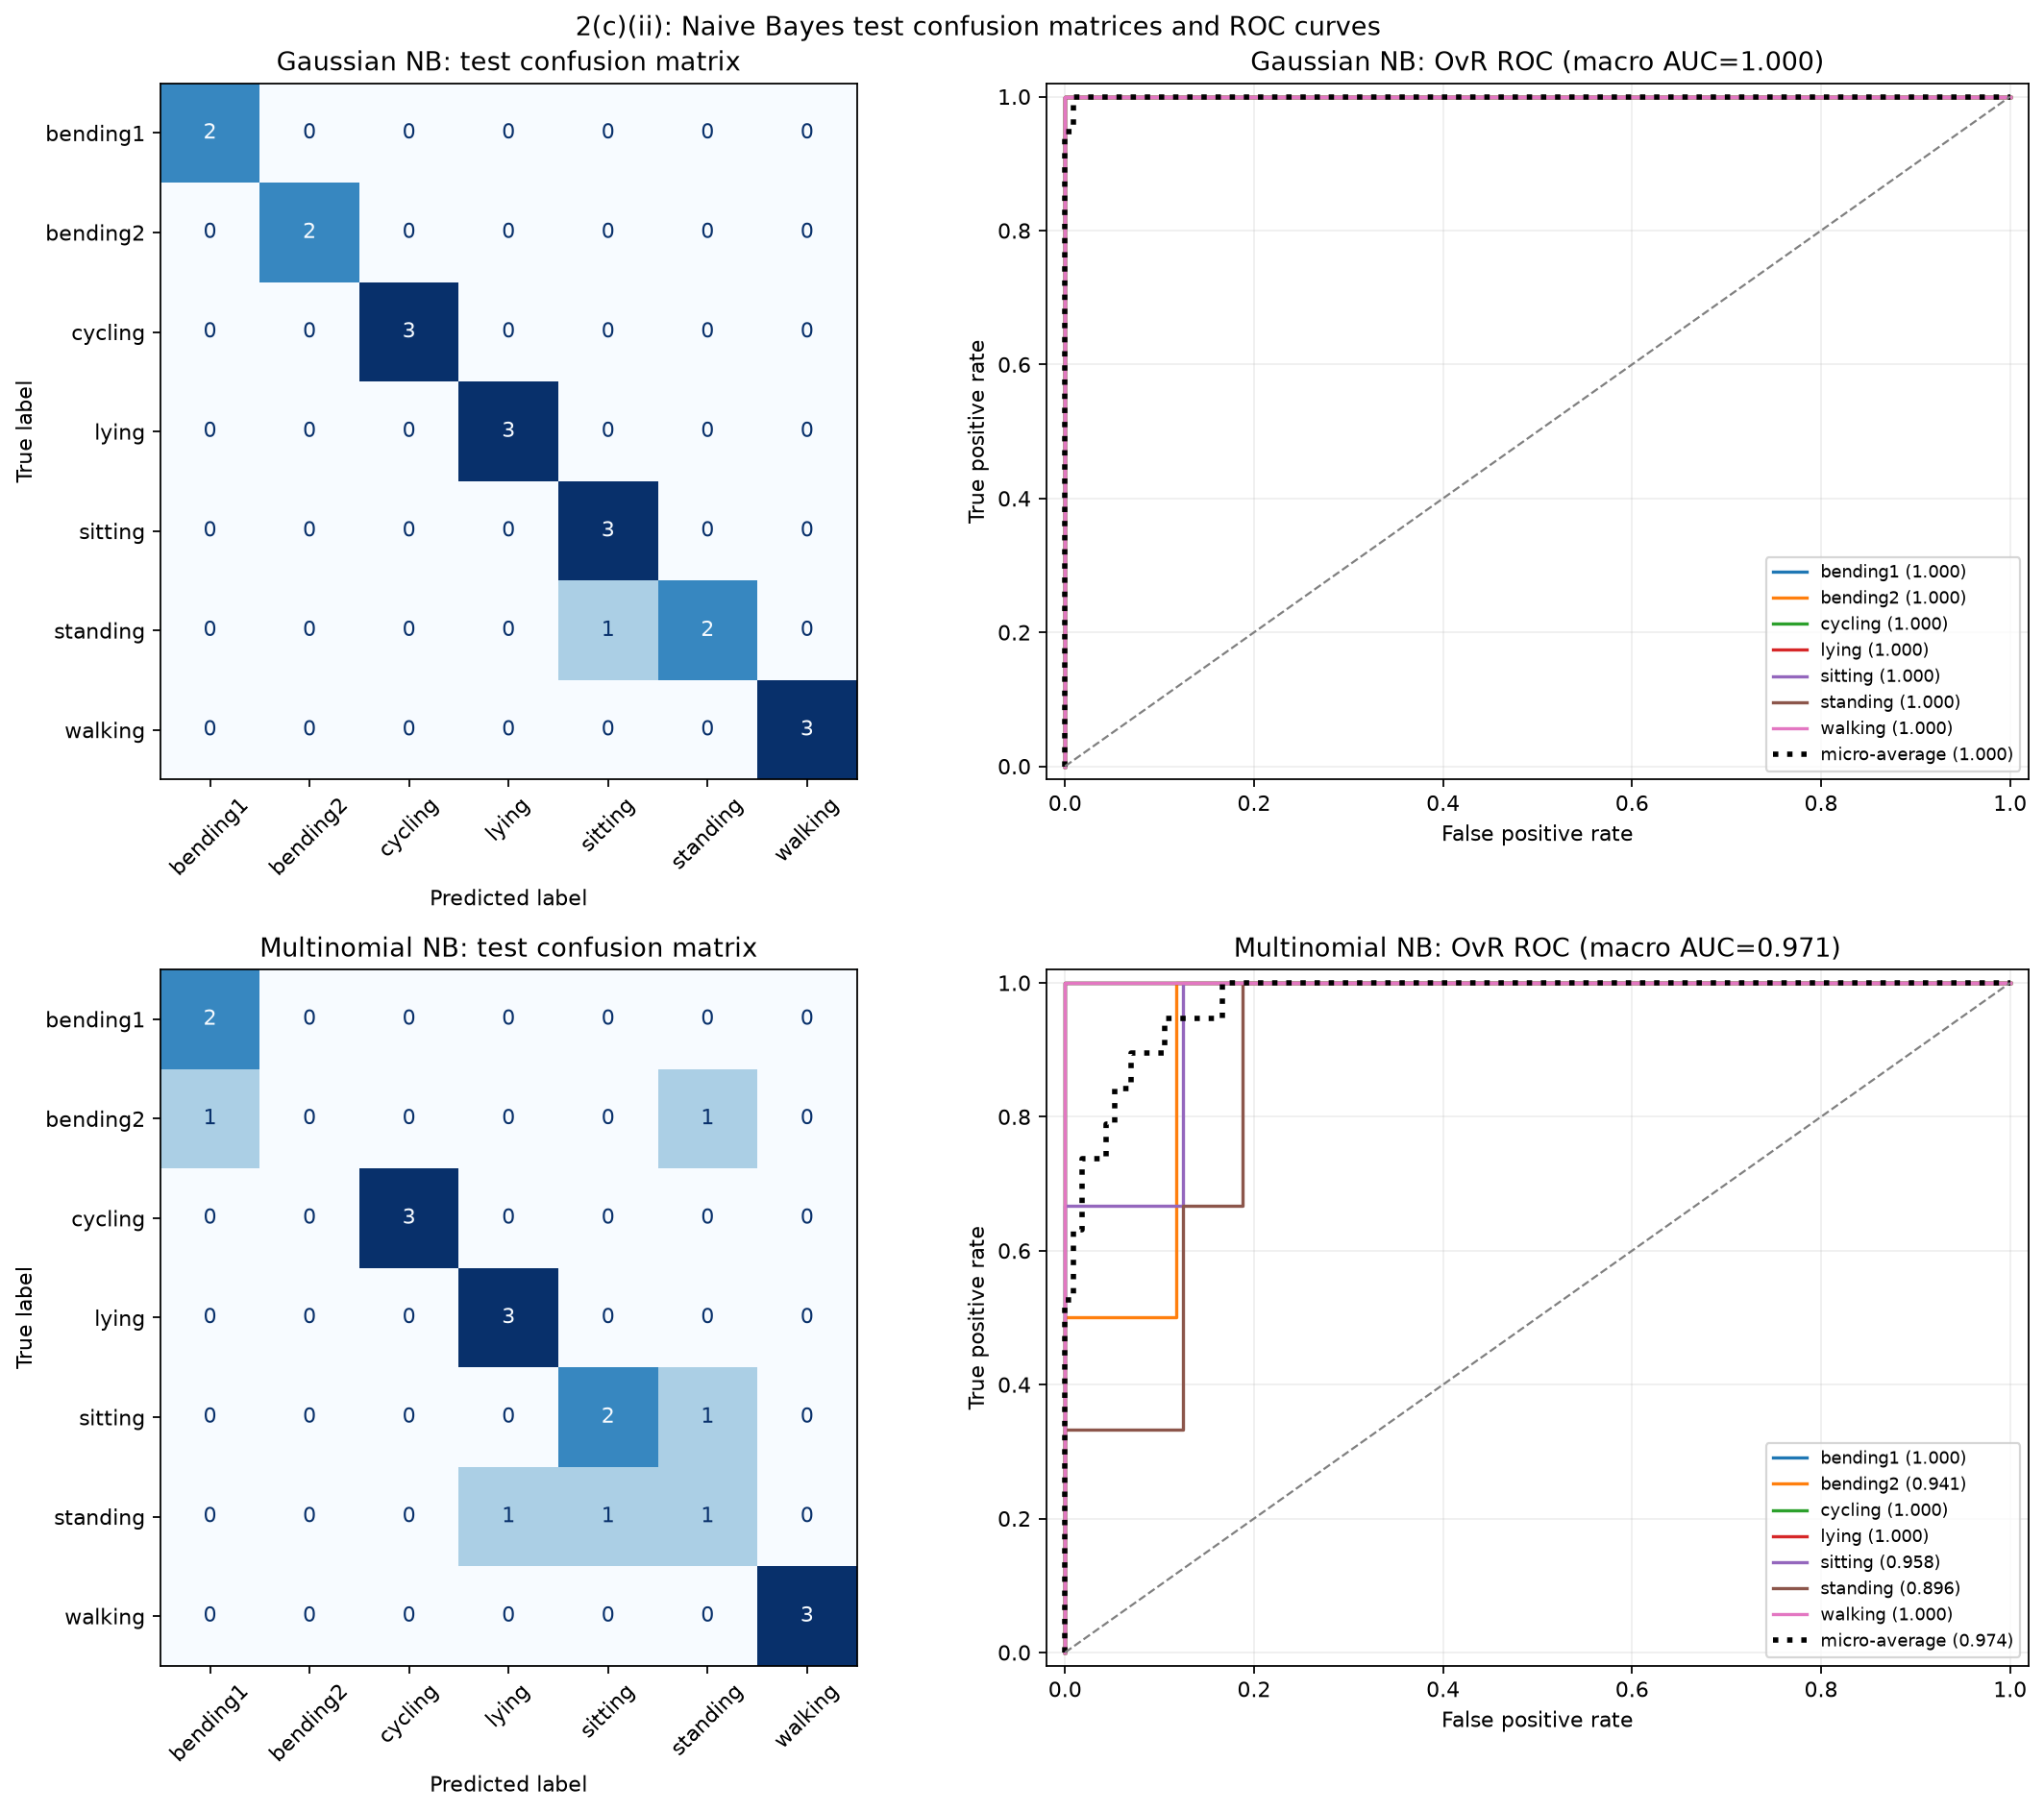

In [ ]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, auc
from sklearn.preprocessing import label_binarize

nb_test_recordings = [np.asarray(read_time_series(path), dtype=float).T for path in test_files]
nb_y_test = np.array([path.parent.name for path in test_files])
nb_test_indicators = label_binarize(nb_y_test, classes=nb_classes)
nb_final_models = {}
nb_results = {}
nb_prediction_rows = []
nb_auc_rows = []
nb_prior_rows = []
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

with threadpool_limits(limits=1):
    for model_index, (method, spec) in enumerate(nb_specs.items()):
        chosen = nb_best[method]
        l = chosen["l"]
        fitted = clone(spec["pipeline"]).set_params(**{f"nb__{spec['parameter']}": chosen["parameter_value"]})
        fitted.fit(features_by_l[l], nb_y_train)
        nb_final_models[method] = fitted
        X_test_nb, test_names_nb = extract_segment_features(nb_test_recordings, l)
        assert test_names_nb == feature_names_by_l[l]
        assert X_test_nb.shape == (19, 42 * l)
        np.testing.assert_array_equal(fitted.classes_, nb_classes)
        if method == "Multinomial NB":
            assert np.all(fitted.named_steps["scale"].transform(X_test_nb) >= 0)
        log_scores = fitted.predict_log_proba(X_test_nb)
        probabilities = fitted.predict_proba(X_test_nb)
        predictions = fitted.predict(X_test_nb)
        assert np.isfinite(log_scores).all()
        np.testing.assert_allclose(probabilities.sum(axis=1), 1, atol=1e-10)
        np.testing.assert_allclose(np.exp(log_scores), probabilities, atol=1e-12)
        np.testing.assert_array_equal(nb_classes[np.argmax(log_scores, axis=1)], predictions)
        matrix = confusion_matrix(nb_y_test, predictions, labels=nb_classes)
        errors = int(np.sum(predictions != nb_y_test))
        accuracy = accuracy_score(nb_y_test, predictions)
        balanced = balanced_accuracy_score(nb_y_test, predictions)
        class_aucs = []
        for column, activity in enumerate(nb_classes):
            class_auc = roc_auc_score(nb_test_indicators[:, column], log_scores[:, column])
            fpr, tpr, _ = roc_curve(nb_test_indicators[:, column], log_scores[:, column])
            class_aucs.append(float(class_auc))
            axes[model_index, 1].plot(fpr, tpr, linewidth=1.5, label=f"{activity} ({class_auc:.3f})")
            nb_auc_rows.append({"model": method, "activity": str(activity), "ovr_auc": float(class_auc)})
        macro_auc = float(np.mean(class_aucs))
        np.testing.assert_allclose(macro_auc, roc_auc_score(nb_test_indicators, log_scores, average="macro"))
        micro_fpr, micro_tpr, _ = roc_curve(nb_test_indicators.ravel(), log_scores.ravel())
        micro_auc = float(auc(micro_fpr, micro_tpr))
        axes[model_index, 1].plot(micro_fpr, micro_tpr, color="black", linestyle=":", linewidth=2.5,
                                  label=f"micro-average ({micro_auc:.3f})")
        axes[model_index, 1].plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
        axes[model_index, 1].set(xlabel="False positive rate", ylabel="True positive rate",
                                title=f"{method}: OvR ROC (macro AUC={macro_auc:.3f})",
                                xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
        axes[model_index, 1].legend(loc="lower right", fontsize=8)
        axes[model_index, 1].grid(alpha=0.2)
        ConfusionMatrixDisplay(matrix, display_labels=nb_classes).plot(
            ax=axes[model_index, 0], cmap="Blues", colorbar=False, values_format="d", xticks_rotation=45)
        axes[model_index, 0].set_title(f"{method}: test confusion matrix")

        priors = (fitted.named_steps["nb"].class_prior_ if method == "Gaussian NB"
                  else np.exp(fitted.named_steps["nb"].class_log_prior_))
        np.testing.assert_allclose(priors, nb_counts / nb_counts.sum())
        nb_prior_rows.extend({"model": method, "activity": str(activity), "class_prior": float(prior)}
                             for activity, prior in zip(nb_classes, priors))
        nb_results[method] = {
            **chosen, "test_errors": errors, "test_error": float(1 - accuracy), "test_accuracy": float(accuracy),
            "test_balanced_accuracy": float(balanced), "test_confusion_matrix": matrix.tolist(),
            "macro_ovr_auc": macro_auc, "micro_ovr_auc": micro_auc, "class_ovr_auc": class_aucs,
        }
        print(f"{method}: {errors}/19 test errors ({1-accuracy:.2%}), accuracy={accuracy:.2%}, "
              f"balanced accuracy={balanced:.2%}, macro AUC={macro_auc:.4f}, micro AUC={micro_auc:.4f}")
        print("Confusion matrix (rows = actual, columns = predicted):")
        print(matrix)
        print("Class prior probabilities:", dict(zip(nb_classes.tolist(), priors.tolist())))
        for path, actual, prediction, log_row, probability_row in zip(
                test_files, nb_y_test, predictions, log_scores, probabilities):
            row = {"model": method, "activity": path.parent.name, "file": path.name,
                   "actual": str(actual), "predicted": str(prediction)}
            row.update({f"log_probability_{activity}": float(value) for activity, value in zip(nb_classes, log_row)})
            row.update({f"probability_{activity}": float(value) for activity, value in zip(nb_classes, probability_row)})
            nb_prediction_rows.append(row)

fig.suptitle("2(c)(ii): Naive Bayes test confusion matrices and ROC curves")
fig.tight_layout()
fig.savefig(figure_root / "2c_ii_nb_test_evaluation.png", dpi=160, bbox_inches="tight")
plt.show()
for filename, rows in (("2c_ii_test_predictions.csv", nb_prediction_rows),
                       ("2c_ii_class_auc.csv", nb_auc_rows), ("2c_ii_class_priors.csv", nb_prior_rows)):
    with (processed_root / filename).open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
nb_summary = {"classes": nb_classes.tolist(), "cv_folds": nb_n_splits, "seed": 42,
              "cv_scoring": "balanced_accuracy", "candidate_pairs": len(nb_cv_rows),
              "fold_fits": len(nb_cv_rows) * nb_n_splits, "models": nb_results,
              "roc_scores": "log posterior probabilities", "priors": "empirical training class frequencies"}
(processed_root / "2c_ii_summary.json").write_text(json.dumps(nb_summary, indent=2) + "\n")


Multinomial L1 logistic regression: l=2, CV accuracy=92.73%, CV balanced accuracy=86.90%, test error=15.79%, macro AUC=0.9557
Gaussian NB: l=1, CV accuracy=91.18%, CV balanced accuracy=90.48%, test error=5.26%, macro AUC=1.0000
Multinomial NB: l=10, CV accuracy=84.07%, CV balanced accuracy=79.17%, test error=26.32%, macro AUC=0.9708


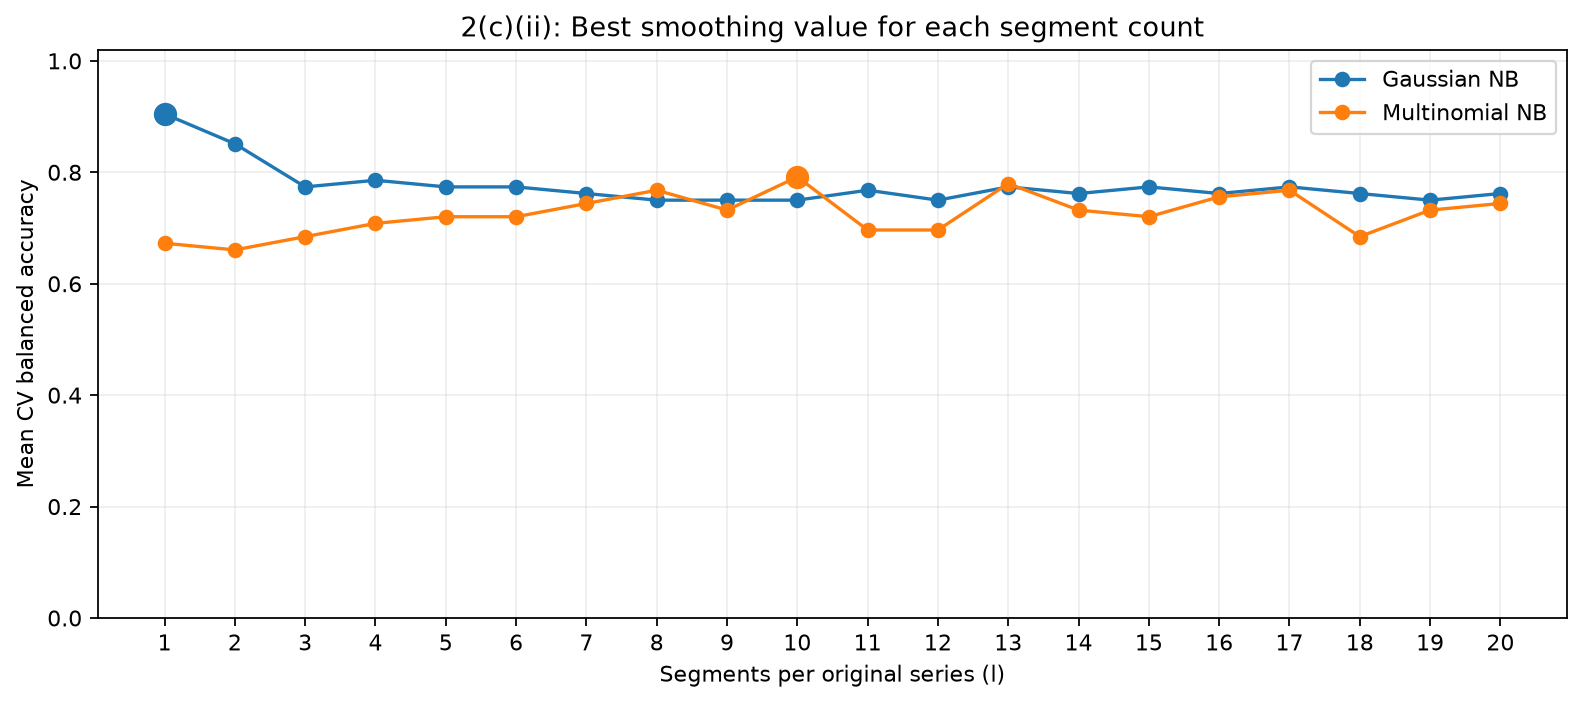

In [ ]:
# Compare with the multinomial L1 model from part (c)(i).
nb_comparison_rows = [{
    "model": "Multinomial L1 logistic regression", "l": multi_summary["best_l"],
    "mean_cv_accuracy": multi_summary["mean_cv_accuracy"],
    "mean_cv_balanced_accuracy": multi_summary["mean_cv_balanced_accuracy"],
    "test_accuracy": multi_summary["test_accuracy"], "test_error": multi_summary["test_error"],
    "macro_ovr_auc": multi_summary["macro_ovr_auc"], "micro_ovr_auc": multi_summary["micro_ovr_auc"],
}]
for method, result in nb_results.items():
    nb_comparison_rows.append({"model": method, "l": result["l"],
        **{key: result[key] for key in ("mean_cv_accuracy", "mean_cv_balanced_accuracy", "test_accuracy", "test_error", "macro_ovr_auc", "micro_ovr_auc")}})
for row in nb_comparison_rows:
    print(f"{row['model']}: l={row['l']}, CV accuracy={row['mean_cv_accuracy']:.2%}, "
          f"CV balanced accuracy={row['mean_cv_balanced_accuracy']:.2%}, "
          f"test error={row['test_error']:.2%}, macro AUC={row['macro_ovr_auc']:.4f}")
with (processed_root / "2c_ii_model_comparison.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(nb_comparison_rows[0]))
    writer.writeheader()
    writer.writerows(nb_comparison_rows)

fig, ax = plt.subplots(figsize=(10, 4.5))
for method in nb_specs:
    scores = [max(row["mean_cv_balanced_accuracy"] for row in nb_cv_rows if row["model"] == method and row["l"] == l)
              for l in range(1, 21)]
    ax.plot(range(1, 21), scores, marker="o", label=method)
    best = nb_best[method]
    ax.scatter([best["l"]], [best["mean_cv_balanced_accuracy"]], s=90, zorder=3)
ax.set(xlabel="Segments per original series (l)", ylabel="Mean CV balanced accuracy",
       title="2(c)(ii): Best smoothing value for each segment count", xticks=range(1, 21), ylim=(0, 1.02))
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(figure_root / "2c_ii_nb_model_selection.png", dpi=160, bbox_inches="tight")
plt.show()


Gaussian NB worked better in my experiment. Its best settings were **$l=1$ and `var_smoothing=0.1`**. The mean CV accuracy was **91.18%**, and the mean CV balanced accuracy was **90.48%**. It got **18 out of 19 test instances correct**, so the test accuracy was **94.74%** and the test error was **5.26%**. The only mistake was predicting a standing instance as sitting. Its macro AUC was **1.0000**, and its micro AUC was **0.9995**.

For Multinomial NB, the best settings were **$l=10$ and $\alpha=0.1$**. Its mean CV accuracy was **84.07%**, and its mean CV balanced accuracy was **79.17%**. It got **14 out of 19 test instances correct**, giving **73.68% test accuracy** and **26.32% test error**. It missed both bending2 instances, one sitting instance, and two standing instances. Its macro AUC was **0.9708**, and its micro AUC was **0.9741**.

I would choose Gaussian NB over Multinomial NB for these results because it had higher CV balanced accuracy and fewer test errors. The continuous features may be a better match for the Gaussian model than the multinomial count model. Still, the Naive Bayes assumptions may not hold completely, since features like mean, median, and quartiles can be closely related.

Gaussian NB also had a lower test error than the L1 model from part (c)(i): **5.26% compared with 15.79%**. However, the L1 model had a higher ordinary CV accuracy. Gaussian NB did best on this test set, but that does not mean it will always be the best model.

The high AUCs show that the models ranked the activities well, but they do not guarantee correct final labels. This is why Gaussian NB had a macro AUC of 1.00 even though it made one mistake. There were only 19 test instances, so I would be careful about drawing a strong conclusion from this comparison alone.


#### (iii) Which Method Works Best for Multiclass Classification?

I would choose **Gaussian Naive Bayes for this experiment**. It had the highest mean CV balanced accuracy, **90.48%**, compared with **86.90%** for L1 multinomial logistic regression and **79.17%** for Multinomial NB. Balanced accuracy was the metric I used to choose the models because the activities have different class sizes.

The test results also favored Gaussian NB. It made only **1 mistake out of 19**, giving a **5.26% test error**. The L1 multinomial model made 3 mistakes (**15.79% error**), and Multinomial NB made 5 mistakes (**26.32% error**). Gaussian NB also had the highest macro AUC, **1.0000**.

The L1 model did have a slightly higher ordinary CV accuracy: **92.73%**, compared with **91.18%** for Gaussian NB. So Gaussian NB was not better on every measure, but it did better on my chosen CV metric and on this test set. Since there are only 19 test instances, I would not conclude that it will always outperform the other methods.


## ISLR Exercise 4.8.3: Why QDA Is Quadratic

Let $\pi_k=P(Y=k)$ be the prior probability of class $k$. Since $X\mid Y=k\sim N(\mu_k,\sigma_k^2)$, its class density is

$$f_k(x)=\frac{1}{\sqrt{2\pi}\,\sigma_k}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).$$

The Bayes classifier chooses the class with the largest posterior probability,

$$P(Y=k\mid X=x)=\frac{\pi_k f_k(x)}{\sum_{j=1}^{K}\pi_j f_j(x)}.$$

The denominator is the same for every class, so I only need to compare $\pi_k f_k(x)$. Taking the logarithm keeps the same ordering. After dropping the common constant $-\tfrac12\log(2\pi)$, I get the score

$$\delta_k(x)=\log\pi_k-\log\sigma_k
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Expanding the squared term gives

$$\delta_k(x)=
-\frac{1}{2\sigma_k^2}x^2
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\log\sigma_k+\log\pi_k.$$

This has the form $A_kx^2+B_kx+C_k$. To find a boundary between classes $k$ and $j$, I set their scores equal:

$$(A_k-A_j)x^2+(B_k-B_j)x+(C_k-C_j)=0.$$

The coefficient of $x^2$ is

$$A_k-A_j=\frac{1}{2\sigma_j^2}-\frac{1}{2\sigma_k^2}.$$

When the two variances are different, this coefficient is nonzero, so the quadratic term does not cancel. A comparison between two classes can therefore have up to two cutoffs. The Bayes rule is **quadratic in general**, rather than linear.

If all the class variances are equal, the $x^2$ term is the same for every class and cancels when comparing them. That gives the linear rule as a special case. Allowing different class variances is what makes QDA quadratic.
